# Dubai Land Department × Reddit: corrected weekly analysis

This notebook implements the **REDDIT AND DLD ANALYSIS** section at the end of the methodology draft (snapshot 9 October 2026). It replaces the downstream analysis in `redditXdld (1).ipynb`. It does not rerun or claim to validate the upstream DeBERTa relevance classifier or the corpus builder.

**Primary scope:** four Reddit counts × four DLD counts = 16 exploratory pairs. The professor-requested audit defines all 11 variables and exports weekly-change and ±8-week checks for all 30 pairs, with comments and sales subdivisions treated as secondary checks. No X/Twitter, sentiment, BERTopic domains, or inherited validation scores enter this analysis.

The draft's 58 observations are **week-start labels**, from 28 July 2025 through 31 August 2026. The final label spans through 6 September; it is not a daily endpoint. Reddit's UTC filter starts at 04:00 Dubai time in the first week. DLD's final observed transaction is 4 September, but the extraction endpoint is unconfirmed. We retain the observed 58 bins and repeat all analyses on 56 conservatively trimmed weeks. Do not describe all 58 as verified complete weeks.

**Lag convention:** `r(k) = corr(Reddit[t], DLD[t+k])`.

```text
k = +2:  Reddit week t  -------->  DLD week t+2  (Reddit precedes)
k =  0:  Reddit week t  <------->  DLD week t    (same week)
k = -2:  DLD week t-2   -------->  Reddit week t (DLD precedes)
```

Association is not causation. Counts measure retained discourse activity, not sentiment, investment, unique people, or speculation.


## 1. Setup and inputs
The default mode reproduces downstream analyses from the embedded, observed weekly aggregates; no private source records are needed. Set RAW_DATA_MODE=True to rerun source aggregation using the configured local/Drive inputs. Required libraries: pandas, numpy, scipy, matplotlib, IPython; raw mode additionally needs pyarrow. Outputs go to DLDxReddit_corrected_results. Aggregate mode does not rerun record-level deduplication or classifier inference.


In [1]:
from pathlib import Path
import sys, json, platform
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from IPython.display import display, Image

RAW_DATA_MODE = False
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB and RAW_DATA_MODE:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/Dubai_Real_Estate_Data')
    REDDIT_PATH = ROOT / 'reddit_data/extended_corpus_output/private/social_eligible.parquet'
    DLD_PATH = ROOT / 'Prof_Student_Folder/DLD_Transactions/DLD_transactions_1year.csv'
    MANIFEST_PATH = ROOT / 'reddit_data/extended_corpus_output/corpus_manifest.json'
    OUT = ROOT / 'DLDxReddit_corrected_results'
else:
    ROOT = Path.cwd()
    REDDIT_PATH = ROOT / 'data/social_eligible.parquet'
    DLD_PATH = ROOT / 'data/DLD_transactions_1year.csv'
    MANIFEST_PATH = ROOT / 'reference/corpus_manifest.json'
    OUT = ROOT / 'DLDxReddit_corrected_results'
OUT.mkdir(parents=True,exist_ok=True)
for path in ([REDDIT_PATH,DLD_PATH,MANIFEST_PATH] if RAW_DATA_MODE else []):
    if not path.is_file():
        raise FileNotFoundError(f'Input missing: {path}. Correct the configured path; do not substitute old data.')
print({'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'scipy':scipy.__version__})


{'python': '3.12.14', 'pandas': '3.0.1', 'numpy': '2.5.3', 'scipy': '1.18.1'}


## 2. Tested functions
Missing weeks remain missing on a regular calendar. Lag alignment occurs **before** dropping missing pairs. Detrending is fitted on each lag's overlapping observations. Partial Pearson and rank-based partial correlation use residuals; the nominal test has `n-3` degrees of freedom for one time control.

All `p_iid` and `q_iid` columns are **independence-based diagnostics**. Weekly autocorrelation can invalidate them. Benjamini–Hochberg correction covers all 80 same-week comparisons (16 pairs × 5 methods), or all 1,584 expanded lag comparisons (16 pairs × 33 lags × 3 transformations) in each coverage/support analysis. It does not repair serial dependence. No significance stars or claims of a proven leading indicator are generated.


In [2]:
"""DLD--Reddit weekly analysis. Positive k means corr(Reddit[t], DLD[t+k]).

All analytical p-values assume independent observations. They are diagnostics,
not time-series-valid evidence. No causal or forecasting interpretation is made.
"""
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
from scipy import stats

REDDIT_VARS = ['reddit_total', 'reddit_posts', 'reddit_dubai', 'reddit_dubairealestate']
DLD_VARS = ['dld_total', 'dld_sales', 'dld_mortgages', 'dld_gifts']
ALL_VARS = REDDIT_VARS + DLD_VARS


def regular_weekly(frame):
    """Restore missing calendar weeks; NEVER compress time or infer zero counts."""
    f = frame.copy()
    f['week'] = pd.to_datetime(f['week'], errors='raise')
    if f.empty or f['week'].isna().any() or f['week'].duplicated().any():
        raise ValueError('Weekly dates must be nonmissing, nonempty and unique.')
    if (f['week'].dt.dayofweek != 0).any():
        raise ValueError('Weeks must be Monday labels.')
    f = f.sort_values('week').set_index('week')
    f = f.reindex(pd.date_range(f.index.min(), f.index.max(), freq='W-MON'))
    f.index.name = 'week'
    return f.reset_index()


def bh_adjust(p):
    p = np.asarray(p, dtype=float)
    out = np.full(p.shape, np.nan)
    valid = np.flatnonzero(np.isfinite(p))
    order = valid[np.argsort(p[valid])]
    if len(order):
        adjusted = p[order] * len(order) / np.arange(1, len(order)+1)
        out[order] = np.clip(np.minimum.accumulate(adjusted[::-1])[::-1], 0, 1)
    return out


def usable(a):
    a = np.asarray(a, float)
    return len(a) > 1 and np.linalg.norm(a-a.mean()) > 1e-12 * max(1., np.linalg.norm(a))


def coefficient(x, y, method='pearson', control=None):
    x, y = np.asarray(x, float), np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    if control is not None:
        control = np.asarray(control, float)
        mask &= np.isfinite(control)
    x, y = x[mask], y[mask]
    n = len(x)
    df = n-2
    if n < 4:
        return np.nan, np.nan, n, df
    if control is not None:
        z = control[mask]
        if method == 'spearman':
            x, y, z = stats.rankdata(x), stats.rankdata(y), stats.rankdata(z)
        design = np.column_stack([np.ones(n), z])
        rank = np.linalg.matrix_rank(design)
        x = x - design @ np.linalg.lstsq(design, x, rcond=None)[0]
        y = y - design @ np.linalg.lstsq(design, y, rcond=None)[0]
        df = n-rank-1  # n-3 for one nonconstant control, NOT n-2
        if not usable(x) or not usable(y) or df <= 0:
            return np.nan, np.nan, n, df
        r = float(np.clip(np.corrcoef(x, y)[0, 1], -1, 1))
        p = 0. if abs(r) >= 1 else float(2*stats.t.sf(abs(r)*np.sqrt(df/(1-r*r)), df))
        return r, p, n, df
    if not usable(x) or not usable(y):
        return np.nan, np.nan, n, df
    fn = {'pearson': stats.pearsonr, 'spearman': stats.spearmanr, 'kendall': stats.kendalltau}[method]
    r, p = fn(x, y)
    return float(r), float(p), n, df


def same_week(frame):
    f = regular_weekly(frame)
    t = np.arange(1, len(f)+1, dtype=float)
    rows = []
    for x in REDDIT_VARS:
        for y in DLD_VARS:
            for method, partial in [('pearson',False), ('spearman',False), ('kendall',False), ('pearson',True), ('spearman',True)]:
                r, p, n, df = coefficient(f[x], f[y], method, t if partial else None)
                rows.append(dict(reddit=x, dld=y, method=('partial_' if partial else '')+method,
                                 correlation=r, p_iid=p, n=n, degrees_freedom=df))
    out = pd.DataFrame(rows)
    out['q_iid_bh_all_80'] = bh_adjust(out.p_iid)
    return out


def lag_profile(frame, x, y, max_lag=16, transform='levels', fixed_support=False, min_n=20):
    """Overlap-specific Pearson; detrending refitted on each lag's paired weeks.

    Missingness is removed AFTER calendar shifting. Fixed support holds the
    Reddit anchor weeks constant across the entire +/-max_lag window.
    """
    f = regular_weekly(frame)
    if transform not in ('levels', 'detrended', 'differences'):
        raise ValueError('Unknown transform')
    if max_lag < 0 or max_lag >= len(f):
        raise ValueError('Invalid lag window')
    xv, yv = f[x].astype(float), f[y].astype(float)
    if transform == 'differences':
        xv, yv = xv.diff(), yv.diff()
    t = np.arange(1, len(f)+1, dtype=float)
    anchor = np.ones(len(f), dtype=bool)
    if fixed_support:
        anchor[:] = False
        anchor[max_lag:len(f)-max_lag] = True
        anchor &= np.isfinite(xv)
        for k in range(-max_lag, max_lag+1):
            anchor &= np.isfinite(yv.shift(-k))
    rows = []
    for k in range(-max_lag, max_lag+1):
        shifted = yv.shift(-k)  # Reddit[t] paired with DLD[t+k]
        mask = anchor & np.isfinite(xv) & np.isfinite(shifted)
        r, p, n, df = coefficient(xv[mask], shifted[mask], control=t[mask] if transform == 'detrended' else None)
        if n < min_n:
            r, p = np.nan, np.nan
        rows.append(dict(reddit=x, dld=y, transform=transform, fixed_support=fixed_support,
                         lag_weeks=k, correlation=r, p_iid=p, n=n, degrees_freedom=df))
    return pd.DataFrame(rows)


def all_lags(frame, max_lag=16, fixed_support=False):
    out = pd.concat([lag_profile(frame,x,y,max_lag,tr,fixed_support)
                     for tr in ('levels','detrended','differences')
                     for x in REDDIT_VARS for y in DLD_VARS], ignore_index=True)
    out['q_iid_bh_all_1584'] = bh_adjust(out.p_iid)
    return out


def peak_summary(profile, window):
    p = profile.loc[profile.lag_weeks.abs() <= window].copy()
    p = p.loc[np.isfinite(p.correlation)]
    if p.empty:
        return dict(window=window, peak_lags='', max_abs_r=np.nan, boundary=False, status='undefined')
    magnitude = p.correlation.abs().max()
    winners = p.loc[np.isclose(p.correlation.abs(), magnitude, rtol=1e-8, atol=1e-10)]
    lags = winners.lag_weeks.astype(int).tolist()
    boundary = any(abs(k) == window for k in lags)
    return dict(window=window, peak_lags=','.join(map(str,lags)), max_abs_r=float(magnitude),
                boundary=boundary, status='boundary maximum' if boundary else 'interior maximum (descriptive)')


def boundary_comparison(profiles):
    rows = []
    for key, group in profiles.groupby(['reddit','dld','transform','fixed_support'], sort=False):
        a, b = peak_summary(group,8), peak_summary(group,16)
        row = dict(zip(['reddit','dld','transform','fixed_support'],key))
        row.update({k+'_8':v for k,v in a.items()})
        row.update({k+'_16':v for k,v in b.items()})
        rows.append(row)
    return pd.DataFrame(rows)


def _unique(frame, keys, audit, label):
    if frame[keys].isna().any().any() or frame[keys].astype(str).apply(lambda s: s.str.strip().eq('')).any().any():
        raise ValueError(label+': missing identity; resolve before counting')
    before = len(frame)
    frame = frame.drop_duplicates()
    audit[label+'_exact_duplicate_rows_removed'] = before-len(frame)
    if frame.duplicated(keys).any():
        raise ValueError(label+': conflicting repeated identifiers; review source records')
    return frame.copy()


def aggregate_inputs(reddit, dld):
    """The supplied eligible corpus is an upstream input, not reclassified here."""
    audit = dict(reddit_input_rows=len(reddit), dld_input_rows=len(dld))
    r = _unique(reddit, ['post_type','id'], audit, 'reddit')
    d = _unique(dld, ['transaction_id'], audit, 'dld')
    if 'platform' in r and not r.platform.eq('reddit').all():
        raise ValueError('Input contains non-Reddit platforms')
    if 'eligible' in r and not r.eligible.eq(True).all():
        raise ValueError('Use the eligible corpus, not all_flags')
    r['timestamp_utc'] = pd.to_datetime(r.timestamp_utc, utc=True, errors='raise')
    d['instance_date'] = pd.to_datetime(d.instance_date, format='%Y-%m-%d', errors='raise')
    if r.timestamp_utc.isna().any() or d.instance_date.isna().any():
        raise ValueError('Missing dates must be resolved before aggregation')
    r['subreddit'] = r.subreddit.astype(str).str.lower().str.strip().str.removeprefix('r/')
    if not r.subreddit.isin(['dubai','dubairealestate']).all():
        raise ValueError('Unexpected subreddit')
    if not r.post_type.isin(['reddit_post','reddit_comment']).all():
        raise ValueError('Unexpected record type')
    if not d.trans_group_en.isin(['Sales','Mortgages','Gifts']).all():
        raise ValueError('Unexpected DLD transaction group; inspect before changing denominator')
    r['week'] = r.timestamp_utc.dt.tz_convert('Asia/Dubai').dt.tz_localize(None).dt.to_period('W-SUN').dt.start_time
    d['week'] = d.instance_date.dt.to_period('W-SUN').dt.start_time
    r['reddit_posts'] = r.post_type.eq('reddit_post').astype(int)
    r['reddit_comments'] = r.post_type.eq('reddit_comment').astype(int)
    r['reddit_dubai'] = r.subreddit.eq('dubai').astype(int)
    r['reddit_dubairealestate'] = r.subreddit.eq('dubairealestate').astype(int)
    for col, label in [('dld_sales','Sales'),('dld_mortgages','Mortgages'),('dld_gifts','Gifts')]:
        d[col] = d.trans_group_en.eq(label).astype(int)
    rw = r.groupby('week').agg(reddit_total=('id','size'),reddit_posts=('reddit_posts','sum'),
                              reddit_comments=('reddit_comments','sum'),reddit_dubai=('reddit_dubai','sum'),
                              reddit_dubairealestate=('reddit_dubairealestate','sum'))
    dw = d.groupby('week').agg(dld_total=('transaction_id','size'),dld_sales=('dld_sales','sum'),
                              dld_mortgages=('dld_mortgages','sum'),dld_gifts=('dld_gifts','sum'))
    start, end = max(rw.index.min(),dw.index.min()), min(rw.index.max(),dw.index.max())
    weekly = regular_weekly(rw.join(dw,how='outer').loc[start:end].reset_index())
    # Retain missing weeks as NaN. Zero filling requires independent capture evidence.
    assert (rw.reddit_total == rw.reddit_posts+rw.reddit_comments).all()
    assert (rw.reddit_total == rw.reddit_dubai+rw.reddit_dubairealestate).all()
    assert (dw.dld_total == dw[DLD_VARS[1:]].sum(axis=1)).all()
    audit.update(reddit_min_utc=str(r.timestamp_utc.min()), reddit_max_utc=str(r.timestamp_utc.max()),
                 dld_min_date=str(d.instance_date.min()),dld_max_date=str(d.instance_date.max()),
                 common_week_labels=len(weekly),first_week=str(start.date()),last_week=str(end.date()))
    return weekly, audit


def coverage_mask(weekly, reddit_start_utc, reddit_end_utc, dld_start_local, dld_end_exclusive_local):
    """Conservative full-week eligibility given declared extraction bounds.

    Observed max transaction date alone does not establish an extraction bound.
    Record the source/assumption for every bound alongside the results.
    """
    rs = pd.Timestamp(reddit_start_utc).tz_convert('Asia/Dubai').tz_localize(None)
    re = pd.Timestamp(reddit_end_utc).tz_convert('Asia/Dubai').tz_localize(None)
    ds, de = pd.Timestamp(dld_start_local), pd.Timestamp(dld_end_exclusive_local)
    w = pd.to_datetime(weekly.week)
    return (w >= max(rs,ds)) & (w+pd.Timedelta(days=7) <= min(re,de))


def file_hash(path):
    h = hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):
            h.update(chunk)
    return h.hexdigest()


def run_analysis(weekly, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True,exist_ok=True)
    weekly = regular_weekly(weekly)
    weekly.to_csv(output_dir/'weekly_aggregates.csv',index=False)
    same = same_week(weekly)
    ccf = all_lags(weekly)
    fixed = all_lags(weekly,fixed_support=True)
    boundary = boundary_comparison(pd.concat([ccf,fixed],ignore_index=True))
    same.to_csv(output_dir/'same_week.csv',index=False)
    ccf.to_csv(output_dir/'lag_profiles.csv',index=False)
    fixed.to_csv(output_dir/'lag_profiles_fixed_support.csv',index=False)
    boundary.to_csv(output_dir/'boundary_comparison.csv',index=False)
    return same, ccf, fixed, boundary


## 3. Regression tests on synthetic data
Synthetic data are used **only for testing**, never in the empirical tables. These tests cover known lag direction, missing calendar weeks, partial-correlation degrees of freedom, constant series, boundary ties, fixed-support sizes, and coverage trimming.


In [3]:
import unittest
import numpy as np
import pandas as pd
from scipy import stats



class AnalysisTests(unittest.TestCase):
    def setUp(self):
        self.rng = np.random.default_rng(873)
        self.weeks = pd.date_range('2025-07-28',periods=58,freq='W-MON')

    def test_known_positive_and_negative_lag(self):
        x = self.rng.normal(size=58)
        y = np.r_[self.rng.normal(size=3), x[:-3]]
        f = pd.DataFrame({'week':self.weeks,'x':x,'y':y})
        p = lag_profile(f,'x','y',8)
        self.assertEqual(p.loc[p.correlation.abs().idxmax(),'lag_weeks'],3)
        self.assertAlmostEqual(p.loc[p.lag_weeks.eq(3),'correlation'].iloc[0],1)
        reverse = lag_profile(f,'y','x',8)
        np.testing.assert_allclose(p.correlation,reverse.correlation.iloc[::-1],atol=1e-12)
        self.assertEqual(p.loc[p.lag_weeks.eq(3),'n'].iloc[0],55)

    def test_missing_week_not_compressed(self):
        f = pd.DataFrame({'week':self.weeks,'x':self.rng.normal(size=58),'y':self.rng.normal(size=58)})
        f = f.drop(index=20)
        p = lag_profile(f,'x','y',8)
        self.assertEqual(p.loc[p.lag_weeks.eq(1),'n'].iloc[0],55)
        self.assertEqual(len(regular_weekly(f)),58)

    def test_partial_matches_formula_and_df(self):
        z = np.arange(58.)
        x = z+self.rng.normal(size=58)*10
        y = z+self.rng.normal(size=58)*10
        r,p,n,df = coefficient(x,y,control=z)
        xy,xz,yz = np.corrcoef([x,y,z])[[0,0,1],[1,2,2]]
        expected = (xy-xz*yz)/np.sqrt((1-xz*xz)*(1-yz*yz))
        self.assertAlmostEqual(r,expected)
        self.assertEqual(df,55)
        self.assertAlmostEqual(p,2*stats.t.sf(abs(r)*np.sqrt(55/(1-r*r)),55))

    def test_constant_and_perfect_trend_undefined(self):
        z=np.arange(58.)
        self.assertTrue(np.isnan(coefficient(z,z,control=z)[0]))
        self.assertTrue(np.isnan(coefficient(np.ones(58),z)[0]))

    def test_fixed_support(self):
        f=pd.DataFrame({'week':self.weeks,'x':self.rng.normal(size=58),'y':self.rng.normal(size=58)})
        p=lag_profile(f,'x','y',16,fixed_support=True)
        self.assertEqual(set(p.n),{26})
        self.assertEqual(len(p),33)

    def test_difference_across_gap_is_not_invented(self):
        f=pd.DataFrame({'week':self.weeks,'x':self.rng.normal(size=58),'y':self.rng.normal(size=58)}).drop(index=20)
        p=lag_profile(f,'x','y',8,transform='differences')
        self.assertEqual(p.loc[p.lag_weeks.eq(0),'n'].iloc[0],55)

    def test_ties_and_window_boundaries(self):
        p=pd.DataFrame({'lag_weeks':[-16,-8,0,8,16],'correlation':[.9,.8,.1,-.8,-.9]})
        self.assertEqual(peak_summary(p,8)['peak_lags'],'-8,8')
        self.assertTrue(peak_summary(p,16)['boundary'])

    def test_conservative_coverage(self):
        f=pd.DataFrame({'week':self.weeks})
        mask=coverage_mask(f,'2025-07-28T00:00:00Z','2026-09-07T00:00:00Z','2025-07-28','2026-09-05')
        self.assertEqual(int(mask.sum()),56)
        self.assertFalse(mask.iloc[0])
        self.assertFalse(mask.iloc[-1])

    def test_bh_missing_values(self):
        np.testing.assert_allclose(bh_adjust([.01,.04,np.nan,.03]),[.03,.04,np.nan,.04],equal_nan=True)

    def test_duplicate_weeks_rejected(self):
        with self.assertRaises(ValueError):
            regular_weekly(pd.DataFrame({'week':[self.weeks[0],self.weeks[0]]}))



result = unittest.TextTestRunner(verbosity=1).run(unittest.defaultTestLoader.loadTestsFromTestCase(AnalysisTests))
assert result.wasSuccessful(), 'Do not proceed with failing analysis tests.'


..........
----------------------------------------------------------------------
Ran 10 tests in 0.161s

OK


## 4. Read and validate source data
The source corpus has already been cleaned. Count unique record identities after detecting duplicate/conflicting keys, validate dates, and verify the corpus checksum. Only counting fields are loaded; post text and usernames are not exported. Missing whole weeks are not converted to zero without capture evidence.


In [4]:
from io import StringIO
if RAW_DATA_MODE:
    reddit = pd.read_parquet(REDDIT_PATH, columns=['id','platform','post_type','subreddit','timestamp_utc','eligible'])
    dld = pd.read_csv(DLD_PATH, usecols=['transaction_id','instance_date','trans_group_en','reg_type_en','reg_type_id'], dtype={'transaction_id':'string'})
    manifest = json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))
    weekly, audit = aggregate_inputs(reddit,dld)
    audit['input_sha256'] = {'reddit':file_hash(REDDIT_PATH),'dld':file_hash(DLD_PATH)}
    assert audit['input_sha256']['reddit'] == manifest['output_sha256'], 'Corpus checksum differs from manifest.'
else:
    dld = None
    weekly_input_all = pd.read_csv(StringIO('week,reddit_total,reddit_posts,reddit_comments,reddit_dubai,reddit_dubairealestate,dld_total,dld_sales,dld_mortgages,dld_gifts,dld_offplan_sales,dld_ready_sales\n2025-07-28,2527,277,2250,807,1720,5184,4147.0,907.0,130.0,2756,1391\n2025-08-04,2340,290,2050,712,1628,5199,4139.0,918.0,142.0,2693,1446\n2025-08-11,2350,273,2077,868,1482,5680,4677.0,790.0,213.0,3408,1269\n2025-08-18,2797,285,2512,596,2201,5619,4632.0,804.0,183.0,3404,1228\n2025-08-25,3178,327,2851,795,2383,5386,4319.0,871.0,196.0,3005,1314\n2025-09-01,2721,315,2406,487,2234,5163,4075.0,829.0,259.0,2675,1400\n2025-09-08,2398,322,2076,623,1775,4492,3593.0,686.0,213.0,2476,1117\n2025-09-15,3114,371,2743,813,2301,6056,5051.0,809.0,196.0,3709,1342\n2025-09-22,2917,315,2602,836,2081,6028,4984.0,850.0,194.0,3598,1386\n2025-09-29,2716,346,2370,647,2069,6121,5056.0,919.0,146.0,3580,1476\n2025-10-06,2737,366,2371,644,2093,5680,4471.0,899.0,310.0,3021,1450\n2025-10-13,3580,426,3154,1107,2473,5370,4295.0,883.0,192.0,2746,1549\n2025-10-20,2625,324,2301,663,1962,5153,4026.0,912.0,215.0,2572,1454\n2025-10-27,2898,367,2531,773,2125,5569,4452.0,858.0,259.0,2927,1525\n2025-11-03,2463,351,2112,527,1936,5654,4508.0,991.0,155.0,2980,1528\n2025-11-10,2435,381,2054,554,1881,5828,4627.0,986.0,215.0,3157,1470\n2025-11-17,2656,369,2287,430,2226,5862,4804.0,904.0,154.0,3384,1420\n2025-11-24,2202,294,1908,509,1693,6018,4789.0,995.0,234.0,3143,1646\n2025-12-01,1743,276,1467,394,1349,3303,2706.0,490.0,107.0,1834,872\n2025-12-08,2349,342,2007,602,1747,5501,4458.0,933.0,110.0,2848,1610\n2025-12-15,2323,312,2011,620,1703,5324,4372.0,781.0,171.0,3024,1348\n2025-12-22,2592,338,2254,677,1915,5527,4533.0,803.0,191.0,3298,1235\n2025-12-29,2116,277,1839,499,1617,3989,3348.0,524.0,117.0,2575,773\n2026-01-05,2873,369,2504,350,2523,4575,3696.0,758.0,121.0,2446,1250\n2026-01-12,2911,380,2531,405,2506,5255,4158.0,902.0,195.0,2692,1466\n2026-01-19,3184,397,2787,532,2652,5473,4314.0,908.0,251.0,2758,1556\n2026-01-26,2972,431,2541,552,2420,5683,4464.0,971.0,248.0,2808,1656\n2026-02-02,2723,366,2357,499,2224,5251,4269.0,815.0,167.0,2766,1503\n2026-02-09,3088,436,2652,745,2343,5795,4656.0,990.0,149.0,2937,1719\n2026-02-16,3232,399,2833,477,2755,5002,3944.0,863.0,195.0,2310,1634\n2026-02-23,3213,334,2879,409,2804,5292,4159.0,896.0,237.0,2549,1610\n2026-03-02,5092,328,4764,572,4520,3394,2627.0,618.0,149.0,1787,840\n2026-03-09,5493,447,5046,672,4821,4495,3588.0,801.0,106.0,2222,1366\n2026-03-16,5255,409,4846,542,4713,3397,2783.0,562.0,52.0,1974,809\n2026-03-23,5327,426,4901,666,4661,3721,3035.0,577.0,109.0,2298,737\n2026-03-30,5189,418,4771,657,4532,4700,3712.0,837.0,151.0,2782,930\n2026-04-06,4162,474,3688,594,3568,4476,3554.0,797.0,125.0,2662,892\n2026-04-13,3401,399,3002,644,2757,3868,3063.0,720.0,85.0,2304,759\n2026-04-20,3337,461,2876,453,2884,4078,3073.0,748.0,257.0,2212,861\n2026-04-27,3302,445,2857,475,2827,3899,2927.0,799.0,173.0,2031,896\n2026-05-04,3210,438,2772,390,2820,3233,2388.0,628.0,217.0,1624,764\n2026-05-11,2458,370,2088,267,2191,4073,3163.0,716.0,194.0,2325,838\n2026-05-18,3071,419,2652,307,2764,4714,3610.0,823.0,281.0,2584,1026\n2026-05-25,2555,288,2267,218,2337,984,831.0,138.0,15.0,704,127\n2026-06-01,3071,411,2660,381,2690,3638,2884.0,566.0,188.0,2208,676\n2026-06-08,3142,402,2740,341,2801,4037,3109.0,691.0,237.0,2312,797\n2026-06-15,2881,386,2495,254,2627,3944,3139.0,607.0,198.0,2186,953\n2026-06-22,2559,346,2213,234,2325,4174,3130.0,731.0,313.0,2238,892\n2026-06-29,3414,485,2929,562,2852,4137,3016.0,924.0,197.0,2004,1012\n2026-07-06,2682,450,2232,371,2311,3832,2732.0,896.0,204.0,1846,886\n2026-07-13,2782,499,2283,294,2488,4270,3202.0,904.0,164.0,2364,838\n2026-07-20,2330,433,1897,325,2005,3879,2942.0,813.0,124.0,1992,950\n2026-07-27,2730,447,2283,503,2227,4616,3530.0,935.0,151.0,2428,1102\n2026-08-03,2959,379,2580,696,2263,4230,3204.0,848.0,178.0,2268,936\n2026-08-10,2844,436,2408,363,2481,3762,2804.0,826.0,132.0,1959,845\n2026-08-17,2909,366,2543,578,2331,4059,3098.0,812.0,149.0,2151,947\n2026-08-24,2296,281,2015,377,1919,3557,2567.0,836.0,154.0,1582,985\n2026-08-31,2666,286,2380,503,2163,3359,2466.0,748.0,145.0,1594,872\n'),parse_dates=['week'])
    weekly = weekly_input_all.drop(columns=['dld_offplan_sales','dld_ready_sales'])
    manifest = json.loads('{\n  "version": "extended-reddit-corpus-v1",\n  "status": "extended Reddit corpus rebuilt using the reviewed Reddit cleaning policy",\n  "platforms": [\n    "reddit"\n  ],\n  "subreddits": [\n    "dubai",\n    "dubairealestate"\n  ],\n  "requested_window_utc_start": "2025-07-28 00:00:00+00:00",\n  "requested_window_utc_end_exclusive": "2026-09-07 00:00:00+00:00",\n  "requested_window_description": "2025-07-28 through 2026-09-06 inclusive",\n  "raw_rows_after_source_id_dedup": 217231,\n  "raw_posts": 30363,\n  "raw_comments": 186868,\n  "eligible_records": 175133,\n  "eligible_posts": 21588,\n  "eligible_comments": 153545,\n  "training_unique_texts": 165580,\n  "duplicate_post_ids_removed": 0,\n  "duplicate_comment_ids_removed": 0,\n  "excluded": {\n    "no_property_evidence": 13312,\n    "contact_only": 9092,\n    "known_reddit_automoderator": 7142,\n    "target_solicitation": 6809,\n    "empty_or_deleted_target": 5448,\n    "reaction_only": 295\n  },\n  "missing_submission_context_eligible": 460,\n  "missing_immediate_parent_eligible": 738,\n  "non_latin_flags": 56,\n  "input_hashes": {\n    "/content/drive/MyDrive/Dubai_Real_Estate_Data/Prof_Student_Folder/Reddit/dubai_data/extended/dubai_posts_realestate_only.csv": "439fb4841e20022620b22f1330a8657f140a2e2d6fb1e898c231a753d839fe9c",\n    "/content/drive/MyDrive/Dubai_Real_Estate_Data/Prof_Student_Folder/Reddit/dubai_data/extended/dubai_comments_realestate_only.csv": "0cdf9c96a05468373eb58736c6f5b09469f0b4789f78439a14dc37e2823cb3e8",\n    "/content/drive/MyDrive/Dubai_Real_Estate_Data/Prof_Student_Folder/Reddit/dubairealestate_data/extended/dubairealestate_raw_posts_extended.csv": "685a31f01da18f0364c955ecd324efb0e04cd5dcee76fb3c9950842471c249f5",\n    "/content/drive/MyDrive/Dubai_Real_Estate_Data/Prof_Student_Folder/Reddit/dubairealestate_data/extended/dubairealestate_raw_comments_extended.csv": "976027c59b2d69b6fbebf3d25617265a826262744687460c8a593fb60f945a11"\n  },\n  "output_sha256": "faf5a0ed0cd229fdad09ffe8bbfc4d653ff7e3957cdbfa4be98a592fbb239fd1",\n  "code_sha256": "b6503f9b54ac925898c7d392fd017251f392d567f04919ecde523718230bc945",\n  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",\n  "pandas": "2.2.3",\n  "window_timezone": "UTC",\n  "analysis_week_timezone": "Asia/Dubai",\n  "unresolved": "This script reproduces the corpus-building/filtering policy. It does not create new human validation labels or perform downstream DLD association selection."\n}')
    audit = {'mode':'Observed aggregate reproduction; source validation not rerun','last_observed_dld_date':'2026-09-04'}
display(pd.DataFrame({'variable':ALL_VARS,'definition':[
    'All retained posts and comments','Retained submissions only','Retained r/dubai records',
    'Retained r/dubairealestate records','All unique DLD registrations','Sales registrations',
    'Mortgage registrations','Gift registrations']}))
print(json.dumps(audit,indent=2))
display(weekly.head())
display(weekly.tail())


{
  "mode": "Observed aggregate reproduction; source validation not rerun",
  "last_observed_dld_date": "2026-09-04"
}


,variable,definition
0,reddit_total,All retained posts and comments
1,reddit_posts,Retained submissions only
2,reddit_dubai,Retained r/dubai records
3,reddit_dubairealestate,Retained r/dubairealestate records
4,dld_total,All unique DLD registrations
5,dld_sales,Sales registrations
6,dld_mortgages,Mortgage registrations
7,dld_gifts,Gift registrations


,week,reddit_total,reddit_posts,reddit_comments,reddit_dubai,reddit_dubairealestate,dld_total,dld_sales,dld_mortgages,dld_gifts
0,2025-07-28,2527,277,2250,807,1720,5184,4147.0,907.0,130.0
1,2025-08-04,2340,290,2050,712,1628,5199,4139.0,918.0,142.0
2,2025-08-11,2350,273,2077,868,1482,5680,4677.0,790.0,213.0
3,2025-08-18,2797,285,2512,596,2201,5619,4632.0,804.0,183.0
4,2025-08-25,3178,327,2851,795,2383,5386,4319.0,871.0,196.0


,week,reddit_total,reddit_posts,reddit_comments,reddit_dubai,reddit_dubairealestate,dld_total,dld_sales,dld_mortgages,dld_gifts
53,2026-08-03,2959,379,2580,696,2263,4230,3204.0,848.0,178.0
54,2026-08-10,2844,436,2408,363,2481,3762,2804.0,826.0,132.0
55,2026-08-17,2909,366,2543,578,2331,4059,3098.0,812.0,149.0
56,2026-08-24,2296,281,2015,377,1919,3557,2567.0,836.0,154.0
57,2026-08-31,2666,286,2380,503,2163,3359,2466.0,748.0,145.0


## 5. Coverage and variable selection
The four Reddit measures distinguish overall activity, initiation of threads, and community composition. Comments remain outside the primary 16-pair table and are analyzed in the separately labelled professor-requested checks. The four DLD measures describe overall registration activity and three transaction groups. Off-plan/existing sales subdivisions remain outside the primary table and are defined and checked in the professor-requested section, using Sales plus the DLD registration-type field. These counts are related and overlapping, not 16 independent replications.

The DLD extraction endpoint is **not established by its last transaction date**. Until the extraction query is verified, using that date plus one day is a conservative sensitivity assumption. If the extraction is confirmed to include the full final Sunday with genuinely zero weekend registrations, update this bound and record the evidence. Do not choose a boundary based on the resulting correlations.


In [5]:
DLD_COVERAGE_START_LOCAL = weekly.week.min()
DLD_COVERAGE_END_EXCLUSIVE_LOCAL = pd.Timestamp(dld.instance_date.max() if RAW_DATA_MODE else audit['last_observed_dld_date']) + pd.Timedelta(days=1)
DLD_COVERAGE_BASIS = 'Conservative proxy from observed date range; extraction endpoint requires verification.'
full_week_mask = coverage_mask(weekly,manifest['requested_window_utc_start'],
    manifest['requested_window_utc_end_exclusive'],DLD_COVERAGE_START_LOCAL,DLD_COVERAGE_END_EXCLUSIVE_LOCAL)
trimmed = weekly.loc[full_week_mask].copy()
audit.update(coverage_basis=DLD_COVERAGE_BASIS,trimmed_week_count=len(trimmed),
    excluded_edge_weeks=weekly.loc[~full_week_mask,'week'].dt.strftime('%Y-%m-%d').tolist())
print('Observed week bins:',len(weekly),'Conservatively trimmed weeks:',len(trimmed))
display(weekly.loc[~full_week_mask,['week']])


Observed week bins: 58 Conservatively trimmed weeks: 56


,week
0,2025-07-28
57,2026-08-31


## 6. Correlations and cross-correlation correction
The ±8-week scan is nested inside a **fixed ±16-week sensitivity window** chosen to examine the previously observed boundary maxima. It is an exploratory extension, not a preregistered lag search. Do not keep widening the window until a preferred peak appears.

Three lag profiles are exported for every pair: levels; linearly detrended paired series; first differences. All report the actual overlap count and require at least 20 pairs. An additional fixed-support analysis uses the same Reddit anchor weeks at every lag (26 for the 58-bin series, before missingness; 24 for the trimmed series). This helps distinguish a moving peak from a changing observation window. Tied maxima are retained. Boundary maxima remain unresolved; interior maxima are descriptive, not validated delay estimates.


In [6]:
same, ccf, ccf_fixed, boundaries = run_analysis(weekly,OUT/'observed_58_weeks')
same_trimmed, ccf_trimmed, fixed_trimmed, boundaries_trimmed = run_analysis(trimmed,OUT/'conservative_complete_weeks')
display(same.pivot(index=['reddit','dld'],columns='method',values='correlation').round(4))
display(boundaries[['reddit','dld','transform','fixed_support','peak_lags_8','peak_lags_16','boundary_16']])
coverage_comparison = same[['reddit','dld','method','correlation','n']].merge(
    same_trimmed[['reddit','dld','method','correlation','n']],on=['reddit','dld','method'],suffixes=('_58','_trimmed'))
coverage_comparison.to_csv(OUT/'coverage_comparison.csv',index=False)
display(coverage_comparison.round(4))
(OUT/'audit.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')


method                                kendall  ...  spearman
reddit                 dld                     ...          
reddit_dubai           dld_gifts      -0.0547  ...   -0.0733
                       dld_mortgages   0.1933  ...    0.2915
                       dld_sales       0.3754  ...    0.5464
                       dld_total       0.3531  ...    0.5265
reddit_dubairealestate dld_gifts       0.0091  ...    0.0027
                       dld_mortgages  -0.1792  ...   -0.2497
                       dld_sales      -0.2849  ...   -0.4047
                       dld_total      -0.2602  ...   -0.3740
reddit_posts           dld_gifts       0.0487  ...    0.0526
                       dld_mortgages   0.0589  ...    0.0978
                       dld_sales      -0.1930  ...   -0.2554
                       dld_total      -0.1305  ...   -0.1894
reddit_total           dld_gifts       0.0316  ...    0.0390
                       dld_mortgages  -0.1012  ...   -0.1241
                       dld_sales      -0.1198  ...   -0.1666
                       dld_total      -0.0975  ...   -0.1407

[16 rows x 5 columns]

,reddit,dld,transform,fixed_support,peak_lags_8,peak_lags_16,boundary_16
0,reddit_total,dld_total,levels,False,8,8,False
1,reddit_total,dld_sales,levels,False,8,8,False
2,reddit_total,dld_mortgages,levels,False,8,11,False
3,reddit_total,dld_gifts,levels,False,1,14,False
4,reddit_posts,dld_total,levels,False,7,7,False
...,...,...,...,...,...,...,...
91,reddit_dubai,dld_gifts,differences,True,-3,10,False
92,reddit_dubairealestate,dld_total,differences,True,8,-13,False
93,reddit_dubairealestate,dld_sales,differences,True,8,-13,False
94,reddit_dubairealestate,dld_mortgages,differences,True,8,-13,False


,reddit,dld,method,correlation_58,n_58,correlation_trimmed,n_trimmed
0,reddit_total,dld_total,pearson,-0.1863,58,-0.1956,56
1,reddit_total,dld_total,spearman,-0.1407,58,-0.1602,56
2,reddit_total,dld_total,kendall,-0.0975,58,-0.1105,56
3,reddit_total,dld_total,partial_pearson,-0.0961,58,-0.1055,56
4,reddit_total,dld_total,partial_spearman,0.0146,58,-0.0146,56
...,...,...,...,...,...,...,...
75,reddit_dubairealestate,dld_gifts,pearson,-0.2217,58,-0.2446,56
76,reddit_dubairealestate,dld_gifts,spearman,0.0027,58,-0.0332,56
77,reddit_dubairealestate,dld_gifts,kendall,0.0091,58,-0.0196,56
78,reddit_dubairealestate,dld_gifts,partial_pearson,-0.1863,58,-0.2051,56


## 7. Figures
Standardization is only for plotting; coefficients use the stated raw, ranked, detrended, or differenced values. Vertical dotted lines identify the original ±8-week scan. There are no misleading white-noise confidence bands.


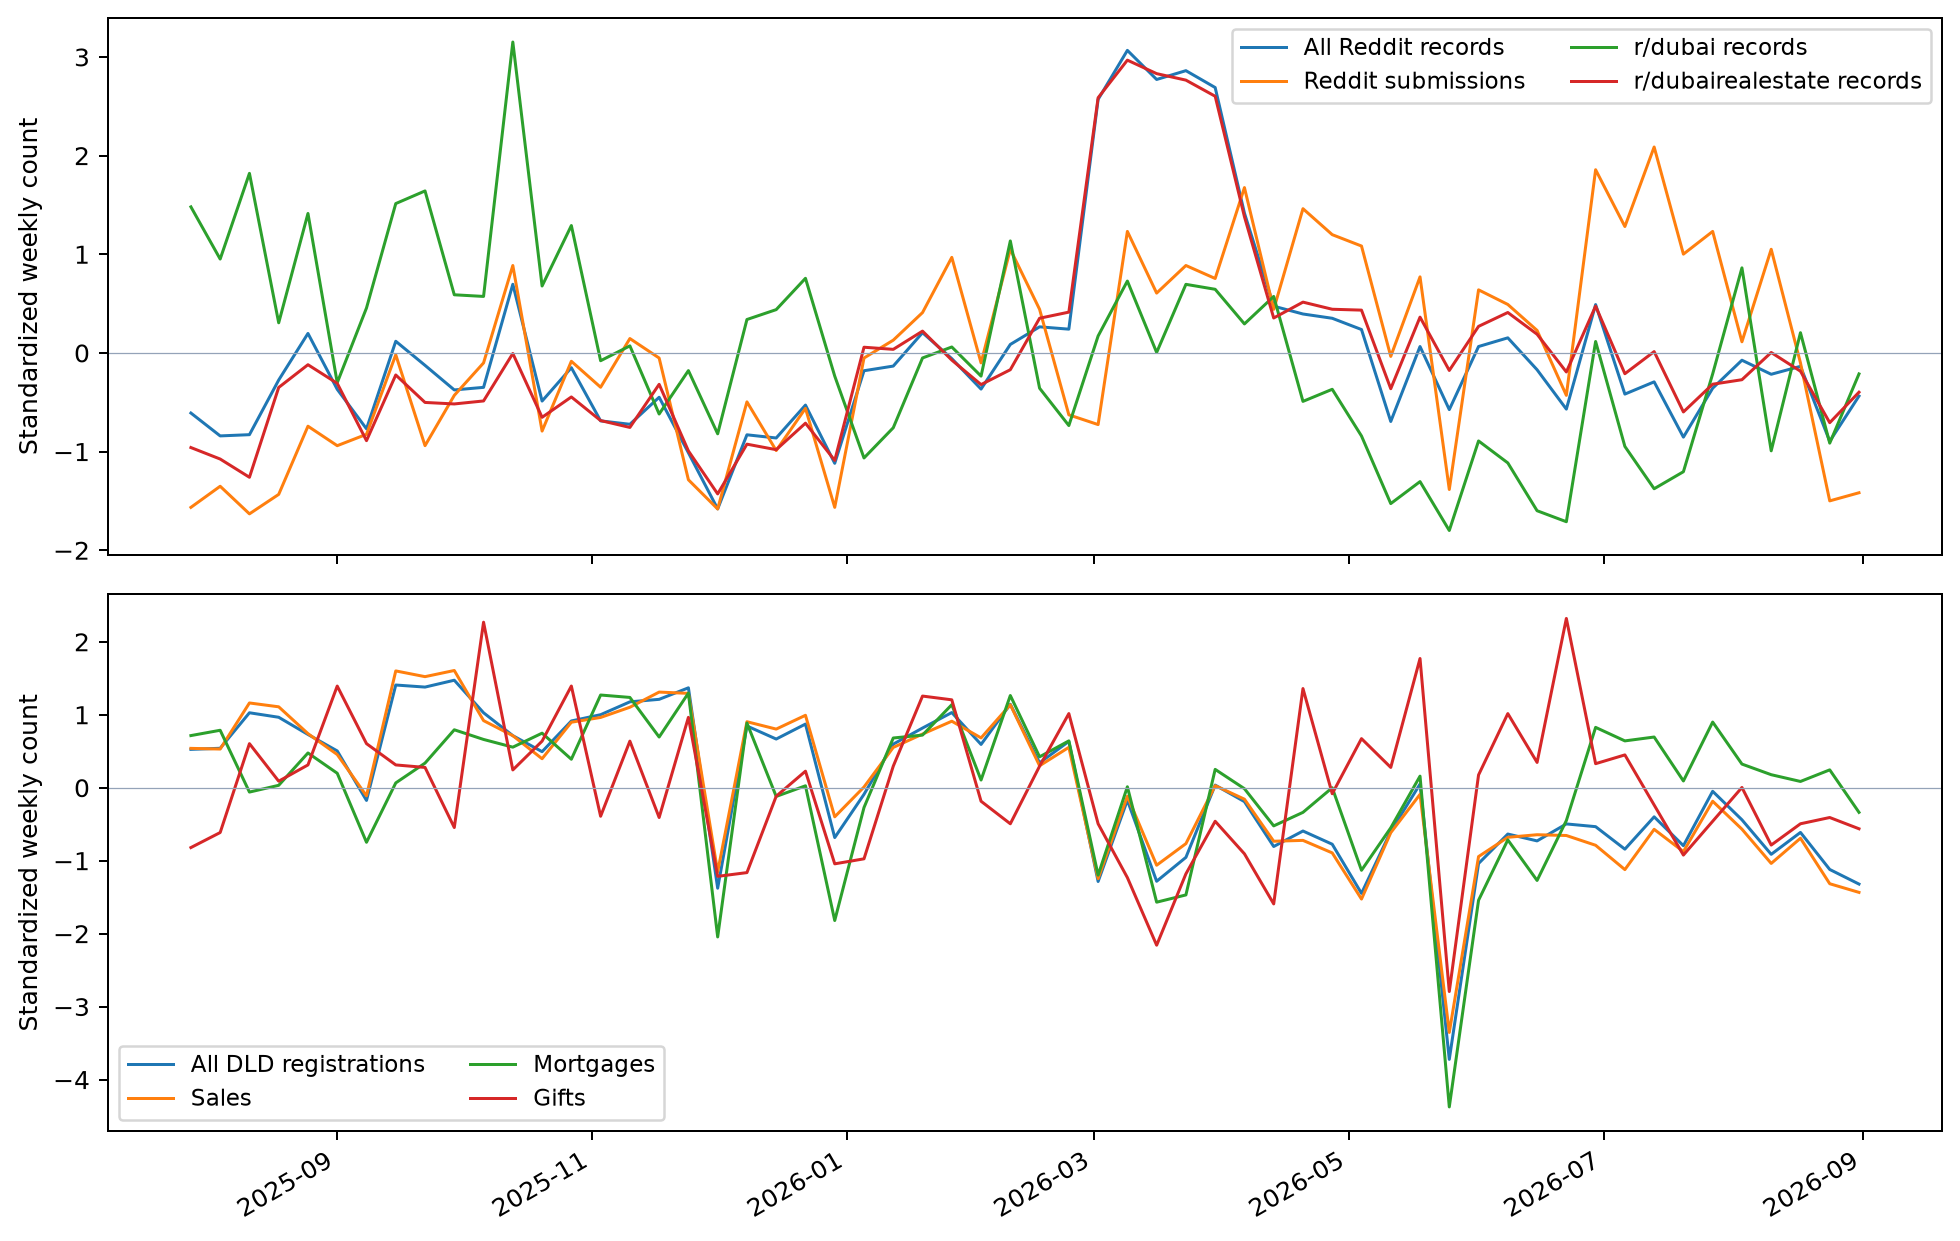

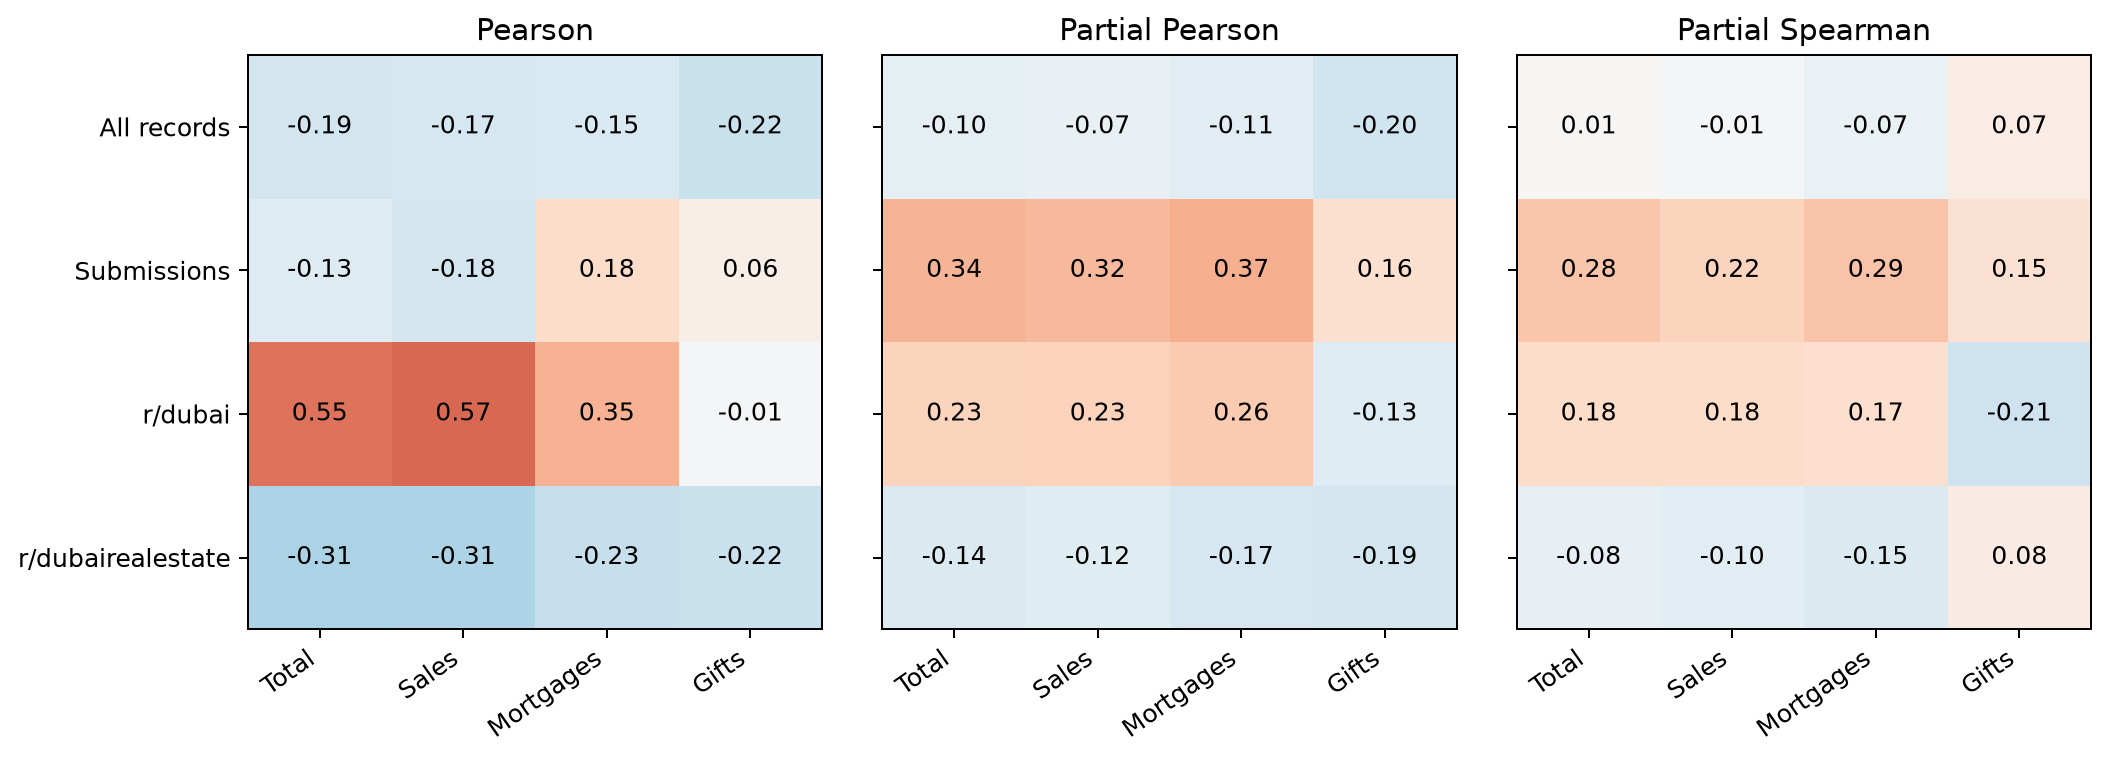

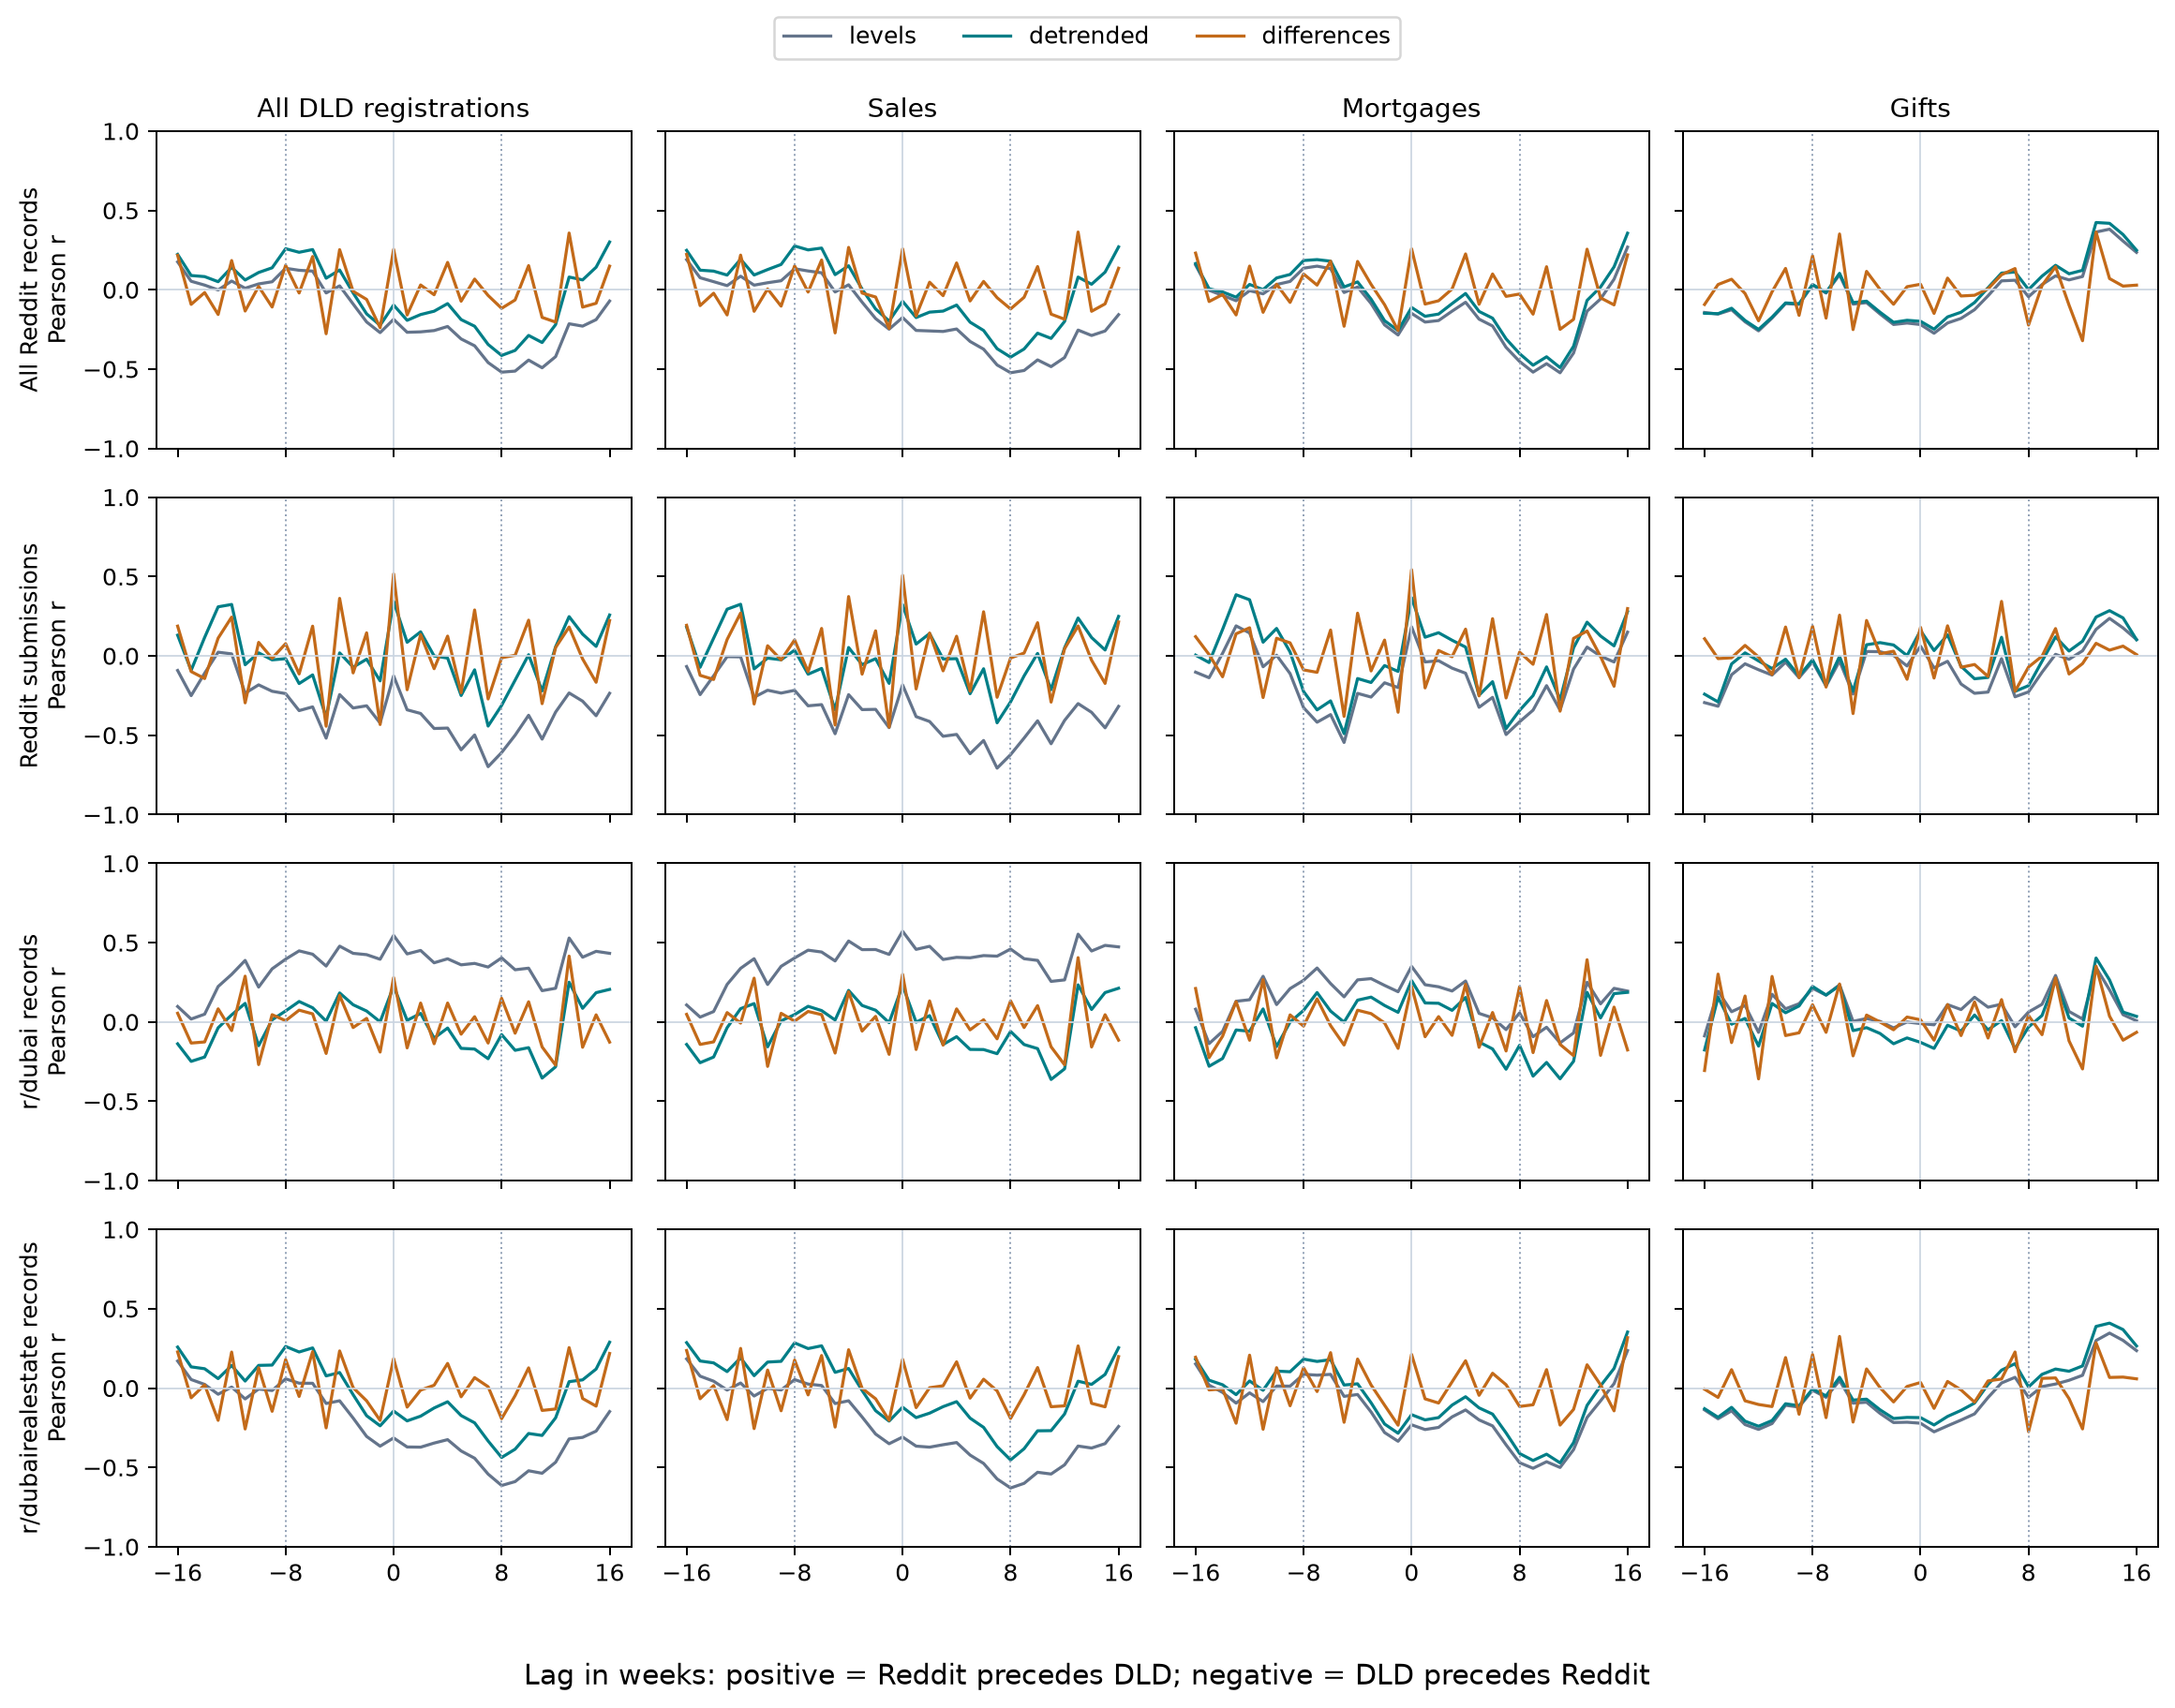

In [7]:
def create_figures(weekly, profiles, same, out):
    out=Path(out)
    titles={'reddit_total':'All Reddit records','reddit_posts':'Reddit submissions',
            'reddit_dubai':'r/dubai records','reddit_dubairealestate':'r/dubairealestate records',
            'dld_total':'All DLD registrations','dld_sales':'Sales','dld_mortgages':'Mortgages','dld_gifts':'Gifts'}
    colors={'levels':'#64748b','detrended':'#007e87','differences':'#c36a19'}
    fig,axes=plt.subplots(4,4,figsize=(13,10),sharex=True,sharey=True)
    for i,x in enumerate(REDDIT_VARS):
        for j,y in enumerate(DLD_VARS):
            ax=axes[i,j]
            for tr,c in colors.items():
                p=profiles.loc[profiles.reddit.eq(x)&profiles.dld.eq(y)&profiles['transform'].eq(tr)]
                ax.plot(p.lag_weeks,p.correlation,color=c,label=tr,linewidth=1.3)
            ax.axhline(0,color='#cbd5e1',lw=.7)
            ax.axvline(0,color='#cbd5e1',lw=.7)
            ax.axvline(-8,color='#94a3b8',ls=':',lw=.8)
            ax.axvline(8,color='#94a3b8',ls=':',lw=.8)
            ax.set_ylim(-1,1)
            ax.set_xticks([-16,-8,0,8,16])
            if i==0: ax.set_title(titles[y],fontsize=11)
            if j==0: ax.set_ylabel(titles[x]+'\nPearson r',fontsize=10)
    fig.legend(*axes[0,0].get_legend_handles_labels(),loc='upper center',ncol=3,bbox_to_anchor=(.5,1.01))
    fig.supxlabel('Lag in weeks: positive = Reddit precedes DLD; negative = DLD precedes Reddit')
    fig.tight_layout(rect=[0,.025,1,.97])
    fig.savefig(out/'lag_profiles.png',dpi=180,bbox_inches='tight')
    plt.close(fig)
    fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
    for cols,ax in zip([REDDIT_VARS,DLD_VARS],axes):
        for col in cols:
            z=(weekly[col]-weekly[col].mean())/weekly[col].std(ddof=1)
            ax.plot(weekly.week,z,label=titles[col],lw=1.2)
        ax.axhline(0,color='#94a3b8',lw=.5)
        ax.set_ylabel('Standardized weekly count')
        ax.legend(ncol=2,fontsize=9)
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(out/'weekly_activity.png',dpi=180,bbox_inches='tight')
    plt.close(fig)
    fig,axes=plt.subplots(1,3,figsize=(12,4),sharey=True)
    for method,ax in zip(['pearson','partial_pearson','partial_spearman'],axes):
        m=same.loc[same.method.eq(method)].pivot(index='reddit',columns='dld',values='correlation').reindex(index=REDDIT_VARS,columns=DLD_VARS)
        im=ax.imshow(m,vmin=-1,vmax=1,cmap='RdBu_r')
        for i in range(4):
            for j in range(4): ax.text(j,i,f'{m.iloc[i,j]:.2f}',ha='center',va='center',fontsize=10)
        ax.set_xticks(range(4),['Total','Sales','Mortgages','Gifts'],rotation=35,ha='right')
        ax.set_yticks(range(4),['All records','Submissions','r/dubai','r/dubairealestate'])
        ax.set_title(method.replace('_',' ').title())
    fig.tight_layout()
    fig.savefig(out/'partial_comparison.png',dpi=180,bbox_inches='tight')
    plt.close(fig)


create_figures(weekly,ccf,same,OUT/'observed_58_weeks')
create_figures(trimmed,ccf_trimmed,same_trimmed,OUT/'conservative_complete_weeks')
for name in ['weekly_activity.png','partial_comparison.png','lag_profiles.png']:
    display(Image(filename=str(OUT/'observed_58_weeks'/name)))


## 8. Interpretation and outstanding provenance
- Compare levels, time-adjusted, and weekly-change results before discussing timing.
- A selected maximum is biased by searching many lags. A boundary maximum does not establish an eight-week response.
- Counts from a selected Reddit corpus do not represent all Dubai residents or buyers; comments within threads and recurring users are dependent.
- The draft reports a 500-post relevance sample, the DeBERTa zero-shot model and threshold 0.4. This notebook takes the resulting corpus as input. Confirm the original labels, candidate-label strings, hypothesis template, model revision, threshold-selection table, and independent held-out performance before treating filtering quality as validated.
- The earlier Reddit findings are reproduced from saved aggregate data below. They are historical references, not extended-period findings: the new corpus has no comparable topic-share labels. The separate within-period activity comparison is not a replication of the earlier semantic relationships.
- DLD registration timing can differ from purchase decisions. Linear detrending does not remove all seasonality or common causes.
- Before inferential claims, use a prespecified model or dependence-aware resampling with explicit assumptions, and independent out-of-sample validation for any forecast claim.

Method references: [SciPy Pearson correlation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html); [statsmodels CCF convention](https://www.statsmodels.org/dev/generated/statsmodels.tsa.stattools.ccf.html). This notebook intentionally defines the lag sign itself and computes overlap-specific Pearson correlations, rather than relying on a library's default sign/normalization.


## 9. Optional audit of saved relevance labels and scores
All 500 gold labels were matched to saved scores during this revision (42 relevant, 458 not relevant). Threshold 0.4 yields TP=32, FP=13, TN=445, FN=10: precision 0.711, recall 0.762, F1 0.736, accuracy 0.954. The following reproduces those diagnostics if the upstream files are available. It does not rerun the classifier. Because the draft says this sample was used to choose the threshold, these are tuning-sample diagnostics, **not independent held-out validation**. Sampling design, annotator procedure, model revision and prompts remain unverified.


In [8]:
"""Audit existing labels/scores; does not train or independently validate a model."""
from pathlib import Path
import json
import pandas as pd



def audit_relevance(gold_path,score_path,out_dir):
    gold=pd.read_csv(gold_path,usecols=['post_id','actual_label'],dtype={'post_id':'string'})
    scores=pd.read_csv(score_path,usecols=['post_id','deberta_score','prediction','is_real_estate'],dtype={'post_id':'string'})
    if gold.post_id.isna().any() or scores.post_id.isna().any() or gold.post_id.duplicated().any() or scores.post_id.duplicated().any():
        raise ValueError('Missing/duplicate post IDs prevent a one-to-one validation merge')
    if not gold.actual_label.isin([0,1]).all():
        raise ValueError('Gold labels must be complete binary labels')
    merged=gold.merge(scores,on='post_id',how='left',validate='one_to_one')
    if merged.deberta_score.isna().any():
        raise ValueError('Some gold IDs have no model score')
    metrics=[]
    for threshold in [.3,.4,.5]:
        pred=merged.deberta_score.ge(threshold).astype(int)
        truth=merged.actual_label
        tp=int(((pred==1)&(truth==1)).sum())
        fp=int(((pred==1)&(truth==0)).sum())
        tn=int(((pred==0)&(truth==0)).sum())
        fn=int(((pred==0)&(truth==1)).sum())
        precision=tp/(tp+fp) if tp+fp else 0.
        recall=tp/(tp+fn) if tp+fn else 0.
        f1=2*precision*recall/(precision+recall) if precision+recall else 0.
        metrics.append(dict(threshold=threshold,tp=tp,fp=fp,tn=tn,fn=fn,precision=precision,recall=recall,f1=f1,accuracy=(tp+tn)/len(truth)))
    out=Path(out_dir)
    out.mkdir(parents=True,exist_ok=True)
    pd.DataFrame(metrics).to_csv(out/'relevance_threshold_diagnostics.csv',index=False)
    report=dict(gold_rows=len(gold),gold_relevant=int(gold.actual_label.sum()),gold_not_relevant=int((gold.actual_label==0).sum()),
                matched_rows=len(merged),score_rows=len(scores),score_equal_04_count=int(scores.deberta_score.eq(.4).sum()),
                stored_prediction_agreement_04=float(scores.prediction.eq(scores.deberta_score.ge(.4).astype(int)).mean()),
                gold_sha256=file_hash(gold_path),scores_sha256=file_hash(score_path),
                caveat='Existing sample diagnostics only. Threshold 0.4 was selected using this sample according to the methodology; not held-out validation. Random sampling and annotator procedure unverified.')
    (out/'relevance_audit.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
    print(json.dumps(report,indent=2))
    print(pd.DataFrame(metrics).round(4).to_string(index=False))
    return report,pd.DataFrame(metrics)



if IN_COLAB:
    VALIDATION_ROOT=ROOT/'Prof_Student_Folder/Reddit/dubai_data/extended'
else:
    VALIDATION_ROOT=ROOT/'data'
gold_path=VALIDATION_ROOT/'gold_sample.csv'
score_path=VALIDATION_ROOT/'dubai_posts_deberta.csv'
if gold_path.is_file() and score_path.is_file():
    relevance_audit,relevance_metrics=audit_relevance(gold_path,score_path,OUT)
    display(relevance_metrics.round(4))
else:
    print('Optional upstream label/score files are absent; downstream analysis is unaffected.')


{
  "gold_rows": 500,
  "gold_relevant": 42,
  "gold_not_relevant": 458,
  "matched_rows": 500,
  "score_rows": 38229,
  "score_equal_04_count": 0,
  "stored_prediction_agreement_04": 1.0,
  "gold_sha256": "d2ea74bb843e5f4b0e430b7fbcd57e99af2ea00e0d47364707b4d9354c6e6f46",
  "scores_sha256": "37d1a99985bf9e590228e16f3e7da9f3e5cc10edf0359d32617b755cd789d582",
  "caveat": "Existing sample diagnostics only. Threshold 0.4 was selected using this sample according to the methodology; not held-out validation. Random sampling and annotator procedure unverified."
}
 threshold  tp  fp  tn  fn  precision  recall     f1  accuracy
       0.3  32  15 443  10     0.6809  0.7619 0.7191     0.950
       0.4  32  13 445  10     0.7111  0.7619 0.7356     0.954
       0.5  31  13 445  11     0.7045  0.7381 0.7209     0.952


,threshold,tp,fp,tn,fn,precision,recall,f1,accuracy
0,0.3,32,15,443,10,0.6809,0.7619,0.7191,0.950
1,0.4,32,13,445,10,0.7111,0.7619,0.7356,0.954
2,0.5,31,13,445,11,0.7045,0.7381,0.7209,0.952


## 10. Professor-requested reproducibility checks
The frozen convention is `r(k)=corr(R[t],D[t+k])`: positive k means Reddit precedes DLD.
The only partial-correlation control is deterministic weekly time t, with an intercept, to assess shared linear drift. No market covariate or lagged response is controlled for. Same-week partial Pearson residualizes the two count series against t; rank-based sensitivity residualizes their average ranks against ranked t. At each lag, detrending is refitted to the paired R[t], D[t+k] on anchor time t; t+k spans the same design with an intercept.

Weekly changes are ΔR[t]=R[t]−R[t−1] and ΔD[t]=D[t]−D[t−1]; correlate aligned changes without bridging missing weeks. All 30 defined count pairs have Pearson and Spearman levels/change coefficients, sample sizes, and 17-value lag profiles for levels, detrended overlaps and differences. These are descriptive secondary checks, not additional significance searches. Four main Reddit–sales pairs receive individual paired time-series figures; standardized plotting does not alter the underlying counts used for correlation.

Boundary maxima are unresolved. A strict interior maximum in absolute correlation is labelled only as the strongest observed association; weaker adjacent lags are checked, but that local pattern is not proof of a unique or robust response delay.

Historical comparison uses the earlier study's 16 Monday labels, 5 January–20 April 2026 (ending 26 April). Its four Reddit topic-share findings are reproduced from the saved companion aggregates embedded below. They cannot be re-estimated across 58 weeks without comparable topic shares. The count-only period comparison instead holds the new measurement definition fixed. Its extended period includes the earlier window; the separate outside-window estimate uses 42 weeks and excludes differences across the intervening gap.


....
----------------------------------------------------------------------
Ran 4 tests in 0.027s

OK


,variable,label,definition,role,aggregation
0,reddit_total,Reddit total activity,All retained posts + comments in both subreddits,Primary,"Weekly count; Monday–Sunday, Dubai local time"
1,reddit_posts,Reddit posts,Retained top-level submissions (post_type = re...,Primary,"Weekly count; Monday–Sunday, Dubai local time"
2,reddit_comments,Reddit comments,Retained comments (post_type = reddit_comment),Secondary,"Weekly count; Monday–Sunday, Dubai local time"
3,reddit_dubai,r/dubai activity,All retained posts + comments in r/dubai,Primary,"Weekly count; Monday–Sunday, Dubai local time"
4,reddit_dubairealestate,r/DubaiRealEstate activity,All retained posts + comments in r/dubaireales...,Primary,"Weekly count; Monday–Sunday, Dubai local time"
5,dld_total,Total DLD transactions,"Unique transaction IDs across Sales, Mortgages...",Primary,"Weekly count; Monday–Sunday, Dubai local time"
6,dld_sales,DLD sales,Unique transaction IDs with trans_group_en = S...,Primary,"Weekly count; Monday–Sunday, Dubai local time"
7,dld_mortgages,DLD mortgages,Unique transaction IDs with trans_group_en = M...,Primary,"Weekly count; Monday–Sunday, Dubai local time"
8,dld_gifts,DLD gifts,Unique transaction IDs with trans_group_en = G...,Primary,"Weekly count; Monday–Sunday, Dubai local time"
9,dld_offplan_sales,Off-plan sales,Sales AND reg_type_en = Off-Plan Properties (r...,Secondary,"Weekly count; Monday–Sunday, Dubai local time"


,reddit,dld,levels_pearson,levels_n,levels_spearman,differences_pearson,differences_n,differences_spearman
0,reddit_total,dld_total,-0.1863,58,-0.1407,0.2547,57,0.4328
1,reddit_total,dld_sales,-0.1748,58,-0.1666,0.2581,57,0.4335
2,reddit_total,dld_mortgages,-0.1488,58,-0.1241,0.2582,57,0.3329
3,reddit_total,dld_gifts,-0.2193,58,0.0390,0.0346,57,0.1191
4,reddit_total,dld_offplan_sales,-0.1513,58,-0.1735,0.2589,57,0.3766
5,reddit_total,dld_ready_sales,-0.1824,58,-0.1431,0.2022,57,0.3798
6,reddit_posts,dld_total,-0.1259,58,-0.1894,0.5168,57,0.4416
7,reddit_posts,dld_sales,-0.1828,58,-0.2554,0.5079,57,0.4371
8,reddit_posts,dld_mortgages,0.1828,58,0.0978,0.5431,57,0.4438
9,reddit_posts,dld_gifts,0.0609,58,0.0526,0.1796,57,0.0546


,period,reddit,dld,n,pearson,partial_pearson,change_n,change_pearson
0,extended_58,reddit_total,dld_sales,58,-0.1748,-0.0725,57,0.2581
1,extended_58,reddit_posts,dld_sales,58,-0.1828,0.3228,57,0.5079
2,extended_58,reddit_dubai,dld_sales,58,0.5717,0.2305,57,0.3002
3,extended_58,reddit_dubairealestate,dld_sales,58,-0.3086,-0.1207,57,0.1811
4,earlier_16_window,reddit_total,dld_sales,16,-0.6604,-0.4763,15,-0.2998
5,earlier_16_window,reddit_posts,dld_sales,16,-0.0099,0.4440,15,0.4990
6,earlier_16_window,reddit_dubai,dld_sales,16,-0.1058,0.2841,15,0.2371
7,earlier_16_window,reddit_dubairealestate,dld_sales,16,-0.6852,-0.5288,15,-0.3776
8,outside_earlier_window,reddit_total,dld_sales,42,-0.0294,0.1807,40,0.4762
9,outside_earlier_window,reddit_posts,dld_sales,42,-0.2261,0.3300,40,0.5138


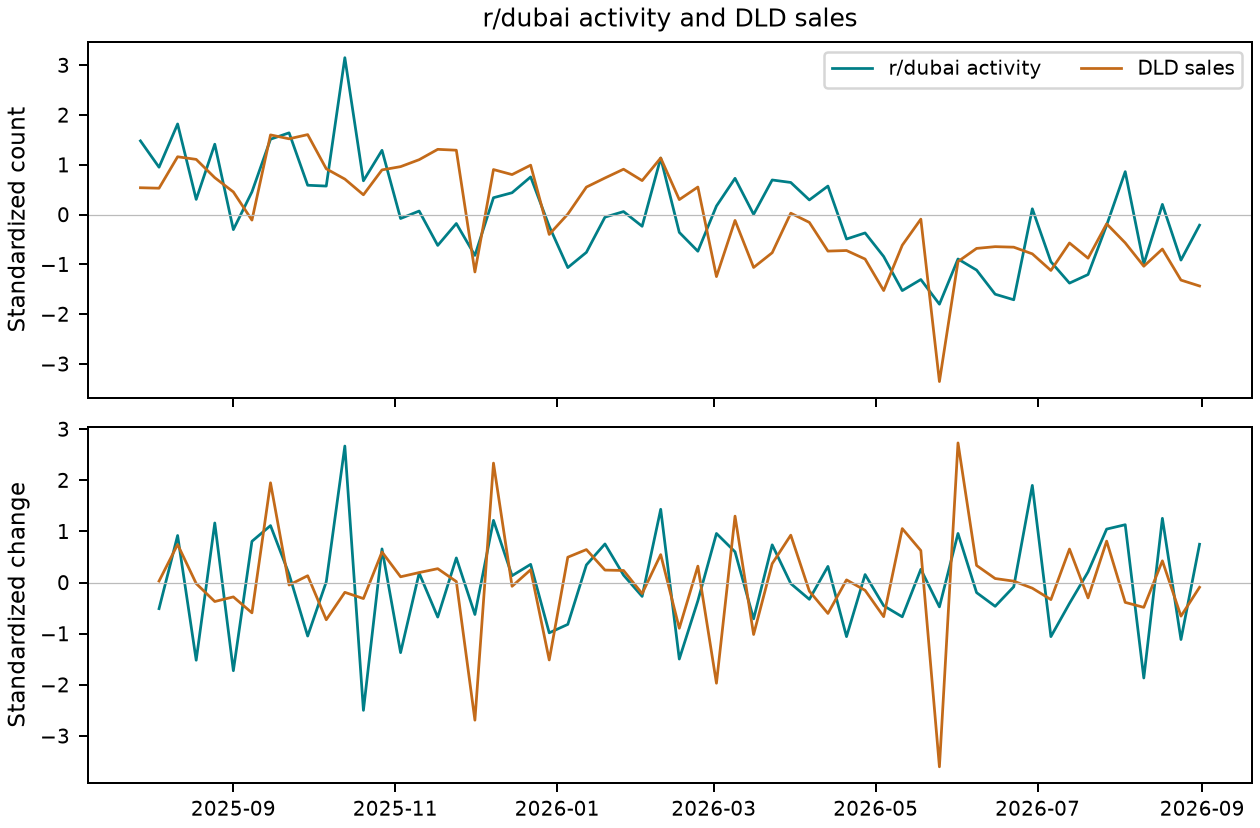

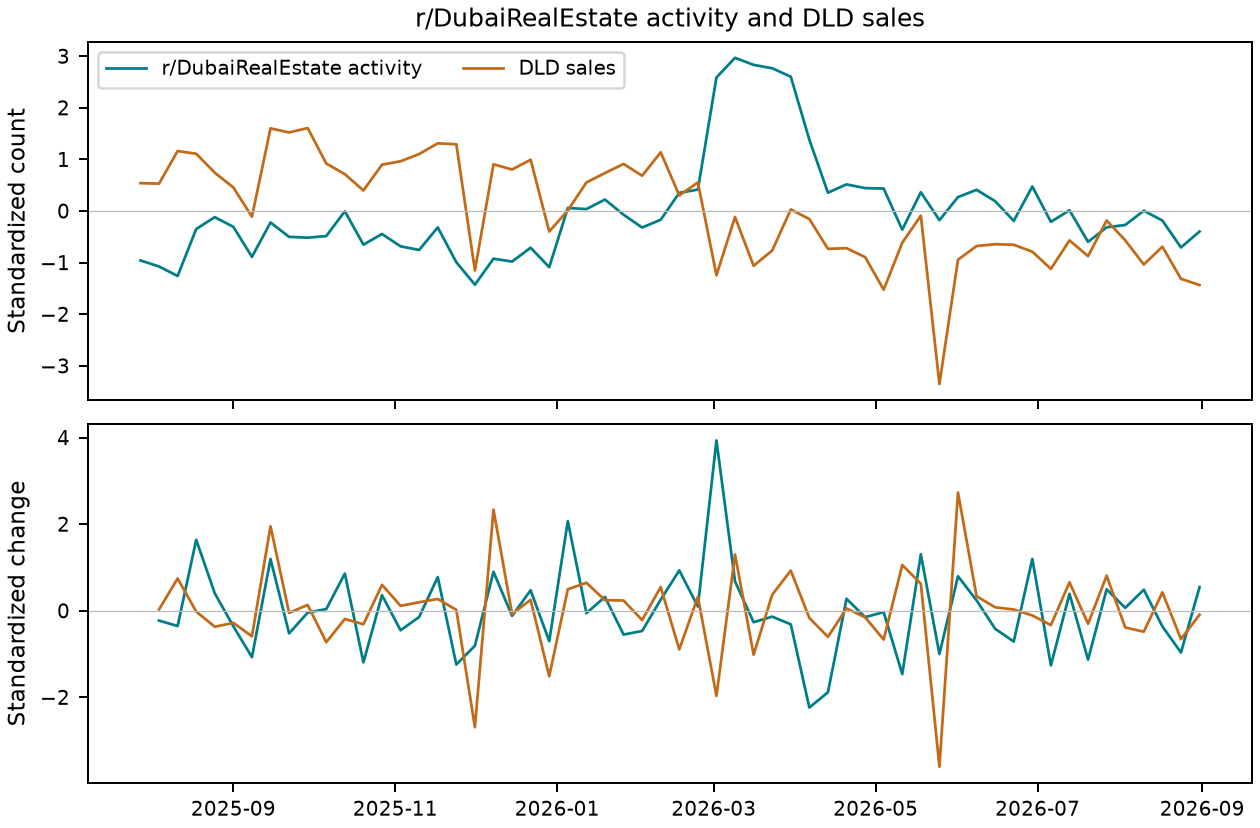

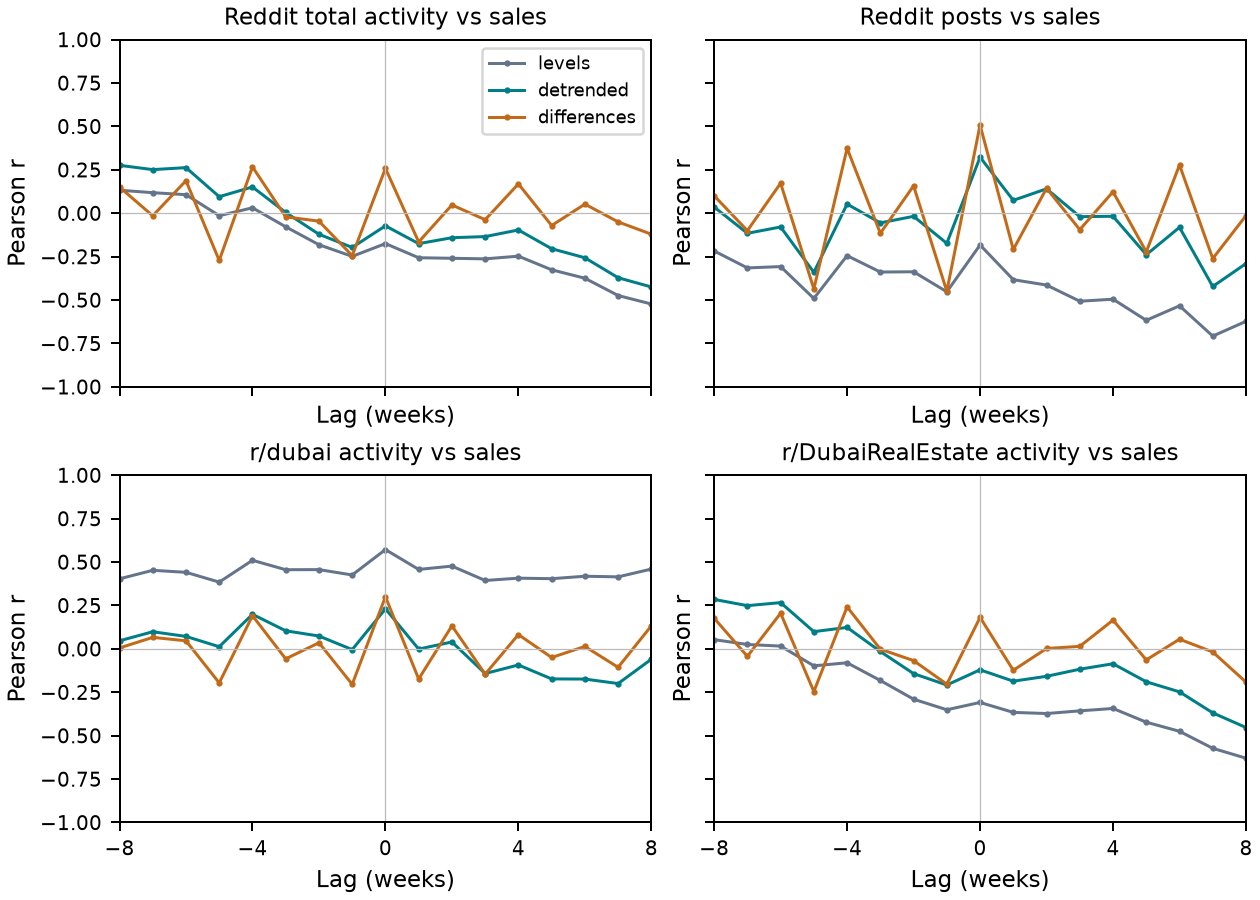

In [9]:
"""Reproducible checks requested by the professor; aggregate-only outputs."""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DICTIONARY = [
    ('reddit_total','Reddit total activity','All retained posts + comments in both subreddits','Primary'),
    ('reddit_posts','Reddit posts','Retained top-level submissions (post_type = reddit_post)','Primary'),
    ('reddit_comments','Reddit comments','Retained comments (post_type = reddit_comment)','Secondary'),
    ('reddit_dubai','r/dubai activity','All retained posts + comments in r/dubai','Primary'),
    ('reddit_dubairealestate','r/DubaiRealEstate activity','All retained posts + comments in r/dubairealestate; case normalized','Primary'),
    ('dld_total','Total DLD transactions','Unique transaction IDs across Sales, Mortgages and Gifts','Primary'),
    ('dld_sales','DLD sales','Unique transaction IDs with trans_group_en = Sales','Primary'),
    ('dld_mortgages','DLD mortgages','Unique transaction IDs with trans_group_en = Mortgages','Primary'),
    ('dld_gifts','DLD gifts','Unique transaction IDs with trans_group_en = Gifts','Primary'),
    ('dld_offplan_sales','Off-plan sales','Sales AND reg_type_en = Off-Plan Properties (reg_type_id = 0)','Secondary'),
    ('dld_ready_sales','Ready/existing sales','Sales AND reg_type_en = Existing Properties (reg_type_id = 1)','Secondary'),
]
FULL_REDDIT = [row[0] for row in DICTIONARY[:5]]
FULL_DLD = [row[0] for row in DICTIONARY[5:]]
LABELS = {row[0]:row[1] for row in DICTIONARY}


def augment_weekly(weekly, dld):
    d = dld.copy()
    if d.transaction_id.isna().any() or d.transaction_id.duplicated().any():
        raise ValueError('DLD transaction IDs must be unique and nonmissing')
    d['instance_date'] = pd.to_datetime(d.instance_date, format='%Y-%m-%d', errors='raise')
    sales = d.trans_group_en.eq('Sales')
    mapping = {'Off-Plan Properties':0, 'Existing Properties':1}
    if not d.loc[sales,'reg_type_en'].isin(mapping).all():
        raise ValueError('Unmapped sales registration category; do not silently classify as ready')
    if not (d.loc[sales,'reg_type_en'].map(mapping).to_numpy() == pd.to_numeric(d.loc[sales,'reg_type_id']).to_numpy()).all():
        raise ValueError('Sales registration labels and IDs disagree')
    d['week'] = d.instance_date.dt.to_period('W-SUN').dt.start_time
    d['dld_offplan_sales'] = (sales & d.reg_type_en.eq('Off-Plan Properties')).astype(int)
    d['dld_ready_sales'] = (sales & d.reg_type_en.eq('Existing Properties')).astype(int)
    seg = d.groupby('week')[['dld_offplan_sales','dld_ready_sales']].sum()
    f = regular_weekly(weekly).merge(seg,on='week',how='left',validate='one_to_one')
    valid = f.dld_sales.notna()
    if not (f.loc[valid,'dld_sales'] == f.loc[valid,['dld_offplan_sales','dld_ready_sales']].sum(axis=1)).all():
        raise ValueError('Off-plan + ready does not reconcile to sales')
    if not (f.loc[f.reddit_total.notna(),'reddit_total'] == (f.reddit_posts + f.reddit_comments).loc[f.reddit_total.notna()]).all():
        raise ValueError('Posts + comments does not reconcile to Reddit total')
    return f


def peak_shape(profile, window=8):
    info = peak_summary(profile,window)
    p = profile.loc[profile.lag_weeks.abs().le(window)].set_index('lag_weeks')
    if info['status']=='undefined' or info['boundary']:
        info['weaker_on_both_adjacent_lags'] = False
    else:
        winners = [int(k) for k in info['peak_lags'].split(',')]
        info['weaker_on_both_adjacent_lags'] = len(winners)==1 and all(
            abs(p.loc[winners[0]+j,'correlation']) < info['max_abs_r']-1e-10 for j in [-1,1])
    return info


def run_professor_checks(weekly, dld, output_dir):
    out=Path(output_dir);out.mkdir(parents=True,exist_ok=True)
    f=regular_weekly(weekly) if dld is None else augment_weekly(weekly,dld)
    dictionary=pd.DataFrame(DICTIONARY,columns=['variable','label','definition','role'])
    dictionary['aggregation']='Weekly count; Monday–Sunday, Dubai local time'
    dictionary.to_csv(out/'variable_dictionary.csv',index=False)
    f.to_csv(out/'weekly_all_variables.csv',index=False)
    f[['week']].join(f[FULL_REDDIT+FULL_DLD].diff()).to_csv(out/'weekly_changes.csv',index=False)
    rows=[]
    for x in FULL_REDDIT:
        for y in FULL_DLD:
            row=dict(reddit=x,dld=y)
            for transform in ['levels','differences']:
                a,b=(f[x],f[y]) if transform=='levels' else (f[x].diff(),f[y].diff())
                for method in ['pearson','spearman']:
                    r,_,n,_=coefficient(a,b,method)
                    row[f'{transform}_{method}']=r;row[f'{transform}_n']=n
            rows.append(row)
    comparison=pd.DataFrame(rows)
    comparison.to_csv(out/'levels_vs_changes_all_30_pairs.csv',index=False)
    profiles=pd.concat([lag_profile(f,x,y,max_lag=8,transform=tr)
        for x in FULL_REDDIT for y in FULL_DLD for tr in ['levels','detrended','differences']],ignore_index=True)
    # Preserve every one of the 17 values, including undefined values, with pair counts.
    profiles.to_csv(out/'lag_profiles_minus8_plus8_all_30_pairs.csv',index=False)
    peaks=[]
    for key,g in profiles.groupby(['reddit','dld','transform'],sort=False):
        peaks.append(dict(zip(['reddit','dld','transform'],key))|peak_shape(g))
    pd.DataFrame(peaks).to_csv(out/'lag_shape_checks.csv',index=False)
    colors={'levels':'#64748b','detrended':'#007e87','differences':'#c36a19'}
    for x in REDDIT_VARS:
        fig,axes=plt.subplots(2,1,figsize=(7,4.6),sharex=True,layout='constrained')
        for ax,change in zip(axes,[False,True]):
            for col,color in [(x,'#007e87'),('dld_sales','#c36a19')]:
                values=f[col].diff() if change else f[col]
                z=(values-values.mean())/values.std(ddof=1)
                ax.plot(f.week,z,label=LABELS[col],color=color,lw=1.1)
            ax.axhline(0,color='#bbb',lw=.5);ax.set_ylabel('Standardized change' if change else 'Standardized count',fontsize=9)
            ax.tick_params(labelsize=8)
        axes[0].legend(fontsize=8,ncol=2);axes[0].set_title(LABELS[x]+' and DLD sales',fontsize=10)
        for ext in ['png','pdf']:fig.savefig(out/f'weekly_pair_{x}.{ext}',dpi=180)
        plt.close(fig)
    fig,axes=plt.subplots(2,2,figsize=(7,5),sharex=True,sharey=True,layout='constrained')
    for x,ax in zip(REDDIT_VARS,axes.flat):
        for tr,color in colors.items():
            p=profiles.loc[profiles.reddit.eq(x)&profiles.dld.eq('dld_sales')&profiles['transform'].eq(tr)]
            ax.plot(p.lag_weeks,p.correlation,label=tr,color=color,lw=1.2,marker='.',ms=3)
        ax.set_title(LABELS[x]+' vs sales',fontsize=9);ax.set_xlim(-8,8);ax.set_ylim(-1,1)
        ax.set_xticks([-8,-4,0,4,8]);ax.axhline(0,color='#bbb',lw=.5);ax.axvline(0,color='#bbb',lw=.5)
        ax.tick_params(labelsize=8);ax.set_xlabel('Lag (weeks)',fontsize=9);ax.set_ylabel('Pearson r',fontsize=9)
    axes[0,0].legend(fontsize=7)
    for ext in ['png','pdf']:fig.savefig(out/f'lag_profiles_minus8_plus8.{ext}',dpi=180)
    plt.close(fig)
    # Common measurement across time; this is not a replication of topic-share findings.
    window=f.week.between('2026-01-05','2026-04-20')
    period_rows=[]
    for label,mask in [('extended_58',np.ones(len(f),bool)),('earlier_16_window',window),('outside_earlier_window',~window)]:
        t=np.arange(1,len(f)+1,dtype=float)
        for x in REDDIT_VARS:
            a,b=f[x].where(mask),f.dld_sales.where(mask)
            r,_,n,_=coefficient(a,b);partial,_,_,_=coefficient(a,b,control=t)
            dr,_,dn,_=coefficient(a.diff(),b.diff())
            period_rows.append(dict(period=label,reddit=x,dld='dld_sales',n=n,pearson=r,partial_pearson=partial,change_n=dn,change_pearson=dr))
    periods=pd.DataFrame(period_rows);periods.to_csv(out/'activity_period_comparison.csv',index=False)
    audit={'lag_convention':'corr(R[t], D[t+k]); positive k = Reddit precedes DLD',
           'control':'One deterministic weekly index t, intercept included; no same-week or lagged market covariates',
           'primary_pairs':16,'all_defined_pairs_for_change_and_lag_checks':30,'lag_values_per_profile':17,
           'offplan_sales':int(f.dld_offplan_sales.sum()),'ready_sales':int(f.dld_ready_sales.sum()),
           'earlier_window':'Monday labels 2026-01-05 to 2026-04-20 (ending Sunday 2026-04-26)',
           'comparison_limit':'Activity counts are not the earlier topic shares; no direct semantic replication claimed'}
    (out/'checks_audit.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')
    return f,comparison,periods


def reproduce_earlier(earlier_domains, earlier_dld, saved_associations, extended_weekly, out):
    out=Path(out)
    rows=[]
    for _,row in saved_associations.loc[saved_associations.platform.eq('reddit')].iterrows():
        series=earlier_domains.loc[earlier_domains.platform.eq('reddit')&earlier_domains.domain_id.eq(row.domain_id),['week','share_all']]
        pair=series.merge(earlier_dld[['week',row.outcome]],on='week',validate='one_to_one').sort_values('week')
        r,_,n,_=coefficient(pair.share_all,pair[row.outcome]);dr,_,dn,_=coefficient(pair.share_all.diff(),pair[row.outcome].diff())
        if not np.isclose(r,row.pearson_r,atol=1e-10) or not np.isclose(dr,row.difference_r,atol=1e-10):
            raise ValueError('Earlier published coefficients do not reproduce from saved aggregates')
        rows.append(dict(domain_id=row.domain_id,outcome=row.outcome,n=n,pearson=r,change_n=dn,change_pearson=dr,
                         extended_replication='Not estimable: extended topic shares unavailable'))
    pd.DataFrame(rows).to_csv(out/'earlier_findings_reproduced.csv',index=False)
    old=earlier_dld.copy();old['week']=pd.to_datetime(old.week)
    checks=extended_weekly.merge(old,on='week',validate='one_to_one')
    for new,previous in [('dld_sales','sales_registrations'),('dld_offplan_sales','offplan_count'),('dld_ready_sales','ready_count')]:
        checks[new+'_minus_prior']=checks[new]-checks[previous]
    checks.to_csv(out/'earlier_dld_count_reconciliation.csv',index=False)



import unittest
import pandas as pd



class ProfessorCheckTests(unittest.TestCase):
    def fixture(self):
        w=pd.DataFrame({'week':['2026-01-05'],'reddit_total':[3],'reddit_posts':[1],'reddit_comments':[2],'dld_sales':[2]})
        d=pd.DataFrame({'transaction_id':['a','b','c'],'instance_date':['2026-01-06']*3,
                        'trans_group_en':['Sales','Sales','Mortgages'],
                        'reg_type_en':['Off-Plan Properties','Existing Properties','Off-Plan Properties'],
                        'reg_type_id':[0,1,0]})
        return w,d

    def test_segments_exclude_mortgages(self):
        w,d=self.fixture();f=augment_weekly(w,d)
        self.assertEqual(f.dld_offplan_sales.iloc[0],1)
        self.assertEqual(f.dld_ready_sales.iloc[0],1)

    def test_unmapped_sales_not_ready(self):
        w,d=self.fixture();d.loc[0,'reg_type_en']='Unknown'
        with self.assertRaises(ValueError):augment_weekly(w,d)

    def test_disagreeing_registration_id_rejected(self):
        w,d=self.fixture();d.loc[0,'reg_type_id']=1
        with self.assertRaises(ValueError):augment_weekly(w,d)

    def test_peak_requires_weaker_neighbors_and_rejects_boundary(self):
        p=pd.DataFrame({'lag_weeks':[-2,-1,0,1,2],'correlation':[.1,.3,.7,.4,.2]})
        self.assertTrue(peak_shape(p,2)['weaker_on_both_adjacent_lags'])
        p.loc[4,'correlation']=.8
        self.assertTrue(peak_shape(p,2)['boundary'])
        self.assertFalse(peak_shape(p,2)['weaker_on_both_adjacent_lags'])



check_result=unittest.TextTestRunner(verbosity=1).run(unittest.defaultTestLoader.loadTestsFromTestCase(ProfessorCheckTests))
assert check_result.wasSuccessful()
weekly_all, change_comparison, period_comparison = run_professor_checks(weekly if RAW_DATA_MODE else weekly_input_all,dld,OUT/'professor_checks')
display(pd.read_csv(OUT/'professor_checks/variable_dictionary.csv'))
display(change_comparison.round(4))
display(period_comparison.round(4))
for name in ['weekly_pair_reddit_dubai.png','weekly_pair_reddit_dubairealestate.png','lag_profiles_minus8_plus8.png']:
    display(Image(filename=str(OUT/'professor_checks'/name)))


In [10]:
from io import StringIO
earlier_domains=pd.read_csv(StringIO('domain_id,domain,platform,week,count,eligible_records,topic_assigned_records,share_all,share_assigned,topic_coverage,share_unique\r\n1,Property Market & Pricing,reddit,2026-01-05,100,2535,1299,0.039447731755424,0.0769822940723633,0.5124260355029586,0.0397590361445783\r\n1,Property Market & Pricing,reddit,2026-01-12,99,2589,1305,0.0382387022016222,0.0758620689655172,0.5040556199304751,0.0394422310756972\r\n1,Property Market & Pricing,reddit,2026-01-19,113,2893,1417,0.0390597995160732,0.0797459421312632,0.4898029726927065,0.0402995720399429\r\n1,Property Market & Pricing,reddit,2026-01-26,94,2699,1361,0.0348277139681363,0.0690668626010286,0.5042608373471656,0.03532506576475\r\n1,Property Market & Pricing,reddit,2026-02-02,86,2535,1230,0.0339250493096646,0.0699186991869918,0.4852071005917159,0.0342857142857142\r\n1,Property Market & Pricing,reddit,2026-02-09,122,2821,1422,0.04324707550514,0.0857946554149085,0.5040765685926977,0.0430691277596815\r\n1,Property Market & Pricing,reddit,2026-02-16,161,2972,1547,0.0541722745625841,0.1040723981900452,0.5205248990578735,0.0523759972251127\r\n1,Property Market & Pricing,reddit,2026-02-23,216,2988,1532,0.072289156626506,0.1409921671018277,0.5127175368139224,0.0716955487597689\r\n1,Property Market & Pricing,reddit,2026-03-02,529,4872,2257,0.1085796387520525,0.234381922906513,0.4632594417077175,0.1102756892230576\r\n1,Property Market & Pricing,reddit,2026-03-09,542,5164,2534,0.1049573973663826,0.2138910812943962,0.4907048799380325,0.1052527646129541\r\n1,Property Market & Pricing,reddit,2026-03-16,483,4926,2352,0.0980511571254567,0.2053571428571428,0.4774665042630938,0.0965674110835401\r\n1,Property Market & Pricing,reddit,2026-03-23,396,5018,2379,0.0789159027500996,0.1664564943253468,0.4740932642487047,0.0788726682887266\r\n1,Property Market & Pricing,reddit,2026-03-30,474,4815,2382,0.0984423676012461,0.198992443324937,0.4947040498442367,0.0968015251006142\r\n1,Property Market & Pricing,reddit,2026-04-06,312,3764,1904,0.0828905419766206,0.1638655462184874,0.5058448459086079,0.0815158124318429\r\n1,Property Market & Pricing,reddit,2026-04-13,197,3071,1589,0.0641484858352328,0.1239773442416614,0.5174210354933246,0.0641622340425532\r\n1,Property Market & Pricing,reddit,2026-04-20,215,3059,1474,0.070284406668846,0.1458616010854816,0.4818568159529258,0.0690921228304405\r\n3,Developers & Property Projects,reddit,2026-01-05,261,2535,1299,0.1029585798816568,0.2009237875288683,0.5124260355029586,0.1044176706827309\r\n3,Developers & Property Projects,reddit,2026-01-12,207,2589,1305,0.0799536500579374,0.1586206896551724,0.5040556199304751,0.0816733067729083\r\n3,Developers & Property Projects,reddit,2026-01-19,217,2893,1417,0.0750086415485655,0.1531404375441072,0.4898029726927065,0.0770328102710413\r\n3,Developers & Property Projects,reddit,2026-01-26,231,2699,1361,0.085587254538718,0.1697281410727406,0.5042608373471656,0.0860578729800826\r\n3,Developers & Property Projects,reddit,2026-02-02,183,2535,1230,0.072189349112426,0.148780487804878,0.4852071005917159,0.0746938775510204\r\n3,Developers & Property Projects,reddit,2026-02-09,207,2821,1422,0.0733782346685572,0.1455696202531645,0.5040765685926977,0.0745566413318856\r\n3,Developers & Property Projects,reddit,2026-02-16,273,2972,1547,0.09185733512786,0.1764705882352941,0.5205248990578735,0.094346167186958\r\n3,Developers & Property Projects,reddit,2026-02-23,192,2988,1532,0.0642570281124498,0.1253263707571801,0.5127175368139224,0.0648997621474685\r\n3,Developers & Property Projects,reddit,2026-03-02,232,4872,2257,0.0476190476190476,0.10279131590607,0.4632594417077175,0.0482456140350877\r\n3,Developers & Property Projects,reddit,2026-03-09,302,5164,2534,0.0584817970565453,0.1191791633780584,0.4907048799380325,0.0592417061611374\r\n3,Developers & Property Projects,reddit,2026-03-16,208,4926,2352,0.0422249289484368,0.0884353741496598,0.4774665042630938,0.043010752688172\r\n3,Developers & Property Projects,reddit,2026-03-23,284,5018,2379,0.0565962534874451,0.1193778898696931,0.4740932642487047,0.0569748580697485\r\n3,Developers & Property Projects,reddit,2026-03-30,232,4815,2382,0.0481827622014537,0.0973971452560873,0.4947040498442367,0.0482948527854268\r\n3,Developers & Property Projects,reddit,2026-04-06,174,3764,1904,0.0462274176408076,0.0913865546218487,0.5058448459086079,0.0466194111232279\r\n3,Developers & Property Projects,reddit,2026-04-13,180,3071,1589,0.058612829697167,0.1132787916928886,0.5174210354933246,0.0598404255319149\r\n3,Developers & Property Projects,reddit,2026-04-20,155,3059,1474,0.050670153644982,0.1051560379918588,0.4818568159529258,0.0504005340453938\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-01-05,86,2535,1299,0.0339250493096646,0.0662047729022324,0.5124260355029586,0.0277108433734939\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-01-12,85,2589,1305,0.0328312089609887,0.0651340996168582,0.5040556199304751,0.0314741035856573\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-01-19,103,2893,1417,0.0356031800898721,0.0726887791107974,0.4898029726927065,0.028530670470756\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-01-26,90,2699,1361,0.0333456835865135,0.0661278471711976,0.5042608373471656,0.0263059000375798\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-02-02,75,2535,1230,0.029585798816568,0.0609756097560975,0.4852071005917159,0.0228571428571428\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-02-09,99,2821,1422,0.0350939383197447,0.0696202531645569,0.5040765685926977,0.0285921100253347\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-02-16,99,2972,1547,0.0333109017496635,0.063994828700711,0.5205248990578735,0.023933402705515\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-02-23,150,2988,1532,0.0502008032128514,0.097911227154047,0.5127175368139224,0.0455317703024125\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-03-02,283,4872,2257,0.0580870279146141,0.1253876827647319,0.4632594417077175,0.0517961570593149\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-03-09,251,5164,2534,0.0486057319907048,0.0990528808208366,0.4907048799380325,0.0412717219589257\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-03-16,290,4926,2352,0.0588712951684937,0.1232993197278911,0.4774665042630938,0.0523159636062861\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-03-23,259,5018,2379,0.0516141889198884,0.108869272803699,0.4740932642487047,0.0458231954582319\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-03-30,220,4815,2382,0.0456905503634475,0.0923593618807724,0.4947040498442367,0.0400338911247617\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-04-06,176,3764,1904,0.0467587672688629,0.0924369747899159,0.5058448459086079,0.0389858233369683\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-04-13,149,3071,1589,0.0485183979159882,0.0937696664568911,0.5174210354933246,0.0388962765957446\r\n9,"Political, Geopolitical & Social Discourse",reddit,2026-04-20,128,3059,1474,0.0418437397842432,0.0868385345997286,0.4818568159529258,0.0350467289719626\r\n'))
earlier_dld=pd.read_csv(StringIO('week,sales_registrations,sales_value_aed,median_sale_amount_aed,mean_sale_amount_aed,offplan_count,offplan_median_amount_aed,ready_count,ready_median_amount_aed\r\n2026-01-05,3841,13393731189.08,1830000.0,3487042.746441031,2533,1943888.0,1308,1602479.25\r\n2026-01-12,4218,15050703685.63,1869444.0,3568208.5551517303,2720,1936444.0,1498,1610000.0\r\n2026-01-19,4165,24046399837.88,1840000.0,5773445.339226891,2596,1646230.6,1569,2480000.0\r\n2026-01-26,4638,18187602497.77,1916360.0,3921432.1901185857,2964,1958264.0,1674,1800000.0\r\n2026-02-02,4304,14204793710.88,1770600.0,3300370.28598513,2814,1816944.0,1490,1700000.0\r\n2026-02-09,4515,18756935137.26,1629000.0,4154359.9418073087,2817,1635888.0,1698,1600000.0\r\n2026-02-16,3859,13828626431.35,1748129.0,3583474.068761337,2234,1670293.5,1625,1900000.0\r\n2026-02-23,4336,13917735977.8,1629500.0,3209809.9579797047,2695,1525466.0,1641,1893000.0\r\n2026-03-02,2396,8258458969.92,1650000.0,3446769.186110184,1605,1630000.0,791,1700000.0\r\n2026-03-09,3731,12571527012.57,1597929.0,3369479.231458054,2373,1635000.0,1358,1430000.0\r\n2026-03-16,2348,7220880564.88,1845812.0,3075332.438194208,1645,1699394.0,703,2750000.0\r\n2026-03-23,3366,10989567087.15,1699500.0,3264874.3574420675,2565,1619000.0,801,2500000.0\r\n2026-03-30,3699,13336884243.06,1690000.0,3605537.778605028,2715,1651888.0,984,2079880.0\r\n2026-04-06,3643,11171550512.56,1756888.0,3066579.8826681306,2788,1749913.5,855,1820000.0\r\n2026-04-13,3021,8981985753.2,1706000.0,2973182.970274744,2247,1651645.0,774,1950000.0\r\n2026-04-20,3149,11406007433.7,1697146.05,3622104.615338203,2296,1659858.0,853,1880000.0\r\n'))
earlier_associations=pd.read_csv(StringIO('domain_id,platform,outcome,specification,forward_registration_lag_weeks,n,pearson_r,spearman_rho,difference_n,difference_r,leave_one_out_min,leave_one_out_max\r\n1,reddit,median_sale_amount_aed,share_all,0,16,-0.5539255314027135,-0.6029411764705882,15,-0.0197540109286869,-0.7092398240973978,-0.4728432887653852\r\n3,reddit,offplan_count,share_all,0,16,0.4104953691670504,0.3117647058823529,15,0.1881355695473717,0.276094988921743,0.519834259026335\r\n3,reddit,ready_count,share_all,0,16,0.7478185319168215,0.7176470588235294,15,0.3604670595266958,0.7111049478839717,0.86013897535029\r\n9,reddit,sales_registrations,share_all,0,16,-0.7826905089555157,-0.6794117647058824,15,-0.4985681069329421,-0.878706862795931,-0.7188744292156658\r\n'))
reproduce_earlier(earlier_domains,earlier_dld,earlier_associations,weekly_all,OUT/'professor_checks')
display(pd.read_csv(OUT/'professor_checks/earlier_findings_reproduced.csv'))
display(pd.read_csv(OUT/'professor_checks/earlier_dld_count_reconciliation.csv'))


,domain_id,outcome,n,pearson,change_n,change_pearson,extended_replication
0,1,median_sale_amount_aed,16,-0.553926,15,-0.019754,Not estimable: extended topic shares unavailable
1,3,offplan_count,16,0.410495,15,0.188136,Not estimable: extended topic shares unavailable
2,3,ready_count,16,0.747819,15,0.360467,Not estimable: extended topic shares unavailable
3,9,sales_registrations,16,-0.782691,15,-0.498568,Not estimable: extended topic shares unavailable


,week,reddit_total,reddit_posts,reddit_comments,reddit_dubai,reddit_dubairealestate,dld_total,dld_sales,dld_mortgages,dld_gifts,dld_offplan_sales,dld_ready_sales,sales_registrations,sales_value_aed,median_sale_amount_aed,mean_sale_amount_aed,offplan_count,offplan_median_amount_aed,ready_count,ready_median_amount_aed,dld_sales_minus_prior,dld_offplan_sales_minus_prior,dld_ready_sales_minus_prior
0,2026-01-05,2873,369,2504,350,2523,4575,3696.0,758.0,121.0,2446,1250,3841,1.339373e+10,1830000.00,3.487043e+06,2533,1943888.0,1308,1602479.25,-145.0,-87,-58
1,2026-01-12,2911,380,2531,405,2506,5255,4158.0,902.0,195.0,2692,1466,4218,1.505070e+10,1869444.00,3.568209e+06,2720,1936444.0,1498,1610000.00,-60.0,-28,-32
2,2026-01-19,3184,397,2787,532,2652,5473,4314.0,908.0,251.0,2758,1556,4165,2.404640e+10,1840000.00,5.773445e+06,2596,1646230.6,1569,2480000.00,149.0,162,-13
3,2026-01-26,2972,431,2541,552,2420,5683,4464.0,971.0,248.0,2808,1656,4638,1.818760e+10,1916360.00,3.921432e+06,2964,1958264.0,1674,1800000.00,-174.0,-156,-18
4,2026-02-02,2723,366,2357,499,2224,5251,4269.0,815.0,167.0,2766,1503,4304,1.420479e+10,1770600.00,3.300370e+06,2814,1816944.0,1490,1700000.00,-35.0,-48,13
5,2026-02-09,3088,436,2652,745,2343,5795,4656.0,990.0,149.0,2937,1719,4515,1.875694e+10,1629000.00,4.154360e+06,2817,1635888.0,1698,1600000.00,141.0,120,21
6,2026-02-16,3232,399,2833,477,2755,5002,3944.0,863.0,195.0,2310,1634,3859,1.382863e+10,1748129.00,3.583474e+06,2234,1670293.5,1625,1900000.00,85.0,76,9
7,2026-02-23,3213,334,2879,409,2804,5292,4159.0,896.0,237.0,2549,1610,4336,1.391774e+10,1629500.00,3.209810e+06,2695,1525466.0,1641,1893000.00,-177.0,-146,-31
8,2026-03-02,5092,328,4764,572,4520,3394,2627.0,618.0,149.0,1787,840,2396,8.258459e+09,1650000.00,3.446769e+06,1605,1630000.0,791,1700000.00,231.0,182,49
9,2026-03-09,5493,447,5046,672,4821,4495,3588.0,801.0,106.0,2222,1366,3731,1.257153e+10,1597929.00,3.369479e+06,2373,1635000.0,1358,1430000.00,-143.0,-151,8


## 11. Dependence-aware sensitivity (12 October 2026)
Paired stationary bootstrap of the four existing same-week Reddit–sales change correlations.
10,000 replicates; expected block lengths 2, 4 and 8 weeks; seed 20261012.
Pointwise percentile intervals assume approximately stationary, weakly dependent changes.
They are exploratory, not simultaneous intervals or post-selection confirmation.
The same row indices resample both series; changes are formed before resampling.
The separate held-out annotation protocol is prepared, but human labels and independent
performance estimates are not yet available. SMDIS and sentiment remain out of scope.


In [11]:
"""Exploratory paired stationary-bootstrap intervals for same-week changes.

Configuration chosen for this revision before inspecting bootstrap outputs.
No selected-lag inference, null permutation p-values or causal claims.
"""
from pathlib import Path
import json
import numpy as np
import pandas as pd


CONFIG = dict(seed=20261012, replicates=10000, expected_block_lengths=[2,4,8],
              confidence=.95, estimand='same-week Pearson correlation of first weekly differences',
              pairs=[(x,'dld_sales') for x in REDDIT_VARS],
              selection='Existing four main sales pairs; exploratory, chosen after prior analyses',
              assumptions='Weakly dependent approximately stationary changes; not established by differencing',
              interval='Pointwise percentile; not simultaneous and not a test of zero correlation')


def stationary_indices(n, replicates, block_length, seed):
    if n < 4 or replicates < 1 or not 1 <= block_length <= n:
        raise ValueError('Invalid bootstrap dimensions')
    rng=np.random.default_rng(seed)
    idx=np.empty((replicates,n),dtype=np.int64)
    idx[:,0]=rng.integers(n,size=replicates)
    for t in range(1,n):
        restart=rng.random(replicates) < 1/block_length
        start=rng.integers(n,size=replicates)
        idx[:,t]=np.where(restart,start,(idx[:,t-1]+1)%n)
    return idx


def bootstrap_correlations(x,y,indices):
    x,y=np.asarray(x,float),np.asarray(y,float)
    if x.shape!=y.shape or x.ndim!=1 or not np.isfinite(x).all() or not np.isfinite(y).all():
        raise ValueError('Require complete aligned one-dimensional series')
    if np.ptp(x)==0 or np.ptp(y)==0:
        raise ValueError('Correlation undefined for constant series')
    a,b=x[indices],y[indices]
    a=a-a.mean(axis=1,keepdims=True);b=b-b.mean(axis=1,keepdims=True)
    den=np.sqrt(np.sum(a*a,axis=1)*np.sum(b*b,axis=1))
    values=np.divide(np.sum(a*b,axis=1),den,out=np.full(len(indices),np.nan),where=den>0)
    return np.clip(values,-1,1)


def run_dependence_checks(weekly,out_dir,replicates=10000):
    f=regular_weekly(weekly)
    columns=REDDIT_VARS+['dld_sales']
    if f[columns].isna().any().any():
        raise ValueError('Missing weeks: bootstrap must not compress the calendar')
    out=Path(out_dir);out.mkdir(parents=True,exist_ok=True)
    rows=[];acf=[]
    for coverage,frame in [('observed_58_weeks',f),('interior_56_weeks',f.iloc[1:-1])]:
        delta=frame[columns].diff().iloc[1:]
        for col in columns:
            for transform,series in [('levels',frame[col]),('differences',delta[col])]:
                for lag in range(1,9):
                    acf.append(dict(coverage=coverage,variable=col,transform=transform,lag=lag,
                                    correlation=series.autocorr(lag),n_pairs=len(series)-lag))
        for length in CONFIG['expected_block_lengths']:
            # Same row indices for every variable preserve contemporaneous dependence.
            idx=stationary_indices(len(delta),replicates,length,CONFIG['seed']+length+len(delta))
            for x in REDDIT_VARS:
                draws=bootstrap_correlations(delta[x],delta.dld_sales,idx)
                finite=draws[np.isfinite(draws)]
                if len(finite)<.99*replicates:
                    raise ValueError('Too many degenerate bootstrap samples')
                lo,hi=np.quantile(finite,[.025,.975],method='linear')
                rows.append(dict(coverage=coverage,reddit=x,dld='dld_sales',n=len(delta),
                    expected_block_length=length,replicates=replicates,valid_replicates=len(finite),
                    correlation=delta[x].corr(delta.dld_sales),ci_low=lo,ci_high=hi))
    result=pd.DataFrame(rows);result.to_csv(out/'stationary_bootstrap_changes.csv',index=False)
    pd.DataFrame(acf).to_csv(out/'autocorrelation_diagnostics.csv',index=False)
    (out/'bootstrap_specification.json').write_text(json.dumps(CONFIG|{'replicates':replicates},indent=2),encoding='utf-8')
    return result



bootstrap_results=run_dependence_checks(weekly_all,OUT/'dependence_checks')
display(bootstrap_results.round(4))


,coverage,reddit,dld,n,expected_block_length,replicates,valid_replicates,correlation,ci_low,ci_high
0,observed_58_weeks,reddit_total,dld_sales,57,2,10000,10000,0.2581,-0.1183,0.5910
1,observed_58_weeks,reddit_posts,dld_sales,57,2,10000,10000,0.5079,0.2578,0.6936
2,observed_58_weeks,reddit_dubai,dld_sales,57,2,10000,10000,0.3002,0.1323,0.4722
3,observed_58_weeks,reddit_dubairealestate,dld_sales,57,2,10000,10000,0.1811,-0.1997,0.5166
4,observed_58_weeks,reddit_total,dld_sales,57,4,10000,10000,0.2581,-0.1087,0.5796
5,observed_58_weeks,reddit_posts,dld_sales,57,4,10000,10000,0.5079,0.2783,0.6762
6,observed_58_weeks,reddit_dubai,dld_sales,57,4,10000,10000,0.3002,0.1626,0.4572
7,observed_58_weeks,reddit_dubairealestate,dld_sales,57,4,10000,10000,0.1811,-0.1948,0.5122
8,observed_58_weeks,reddit_total,dld_sales,57,8,10000,10000,0.2581,-0.0778,0.5568
9,observed_58_weeks,reddit_posts,dld_sales,57,8,10000,10000,0.5079,0.2983,0.6514
